# 🛒 Segmentação de Clientes com K-Means

**Autor:** Rafael R. Silva · **Metodologia:** CRISP-DM · **Tipo de problema:** aprendizado não supervisionado (clusterização)

> **Resumo:** agrupamos **2.203 clientes** de uma empresa varejista em **4 perfis de comportamento de compra**, para que o time de marketing direcione o lançamento de um novo produto ao público com maior chance de compra.

---

### 📑 Sumário
- **FASE 01:** Entendimento do Negócio
- **FASE 02:** Preparação dos Dados
- **FASE 03:** Modelagem dos Dados
- **FASE 04:** Avaliação
- **FASE 05:** Implantação
- **Insights** e **Próximos Passos**

> ℹ️ **Sobre esta versão (v2):** estrutura e anotações reorganizadas no padrão CRISP-DM, com validações extras do modelo (Silhouette, PCA, sensibilidade aos pesos e comparação com outro algoritmo), Pipeline de produção e app Streamlit. Executado com Python 3.13, pandas 3.0 e scikit-learn 1.9.

# FASE 01: ENTENDIMENTO DO NEGÓCIO

## 🏢 Contexto

Uma empresa varejista vai lançar um **novo produto** e quer oferecê-lo à sua base de clientes. Enviar a campanha para **todos** é caro e pouco eficiente: parte dos clientes não tem perfil para comprar e pode até se incomodar com ofertas irrelevantes.

**Fonte dos dados:** [Customer Personality Analysis – Kaggle](https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis)

## 🎯 Objetivo

Agrupar os clientes por **semelhança de perfil e de comportamento de compra** (quem são, quanto gastam, o que compram, por qual canal e como reagem a campanhas) e descrever cada grupo, para que o marketing saiba **com quem falar e como falar**.

> **Pergunta de negócio:** *Quais grupos de clientes existem na base e qual deles deve ser priorizado na campanha do novo produto?*

**Stakeholder:** Gerente de Estratégia de Marketing.

## 🧩 Formato da solução

| Item | Definição |
|---|---|
| **Granularidade** | Cliente (uma linha = um cliente) |
| **Tipo de problema** | Segmentação (clusterização) – **não supervisionado**: não existe uma resposta "certa" para o modelo aprender, ele descobre os grupos sozinho |
| **Método principal** | K-Means, com o número de grupos definido pelo Método do Cotovelo (Elbow) e pelo Silhouette Score |
| **Entrega** | Perfil de cada segmento + recomendação de ação de marketing + modelo salvo para classificar novos clientes |

## 🗺️ Planejamento da solução (CRISP-DM)

| Fase | O que será feito |
|---|---|
| **01. Entendimento do negócio** | Definir o problema, o objetivo e o formato da entrega |
| **02. Preparação dos dados** | Coletar, limpar, explorar (EDA), criar variáveis e analisar correlações |
| **03. Modelagem** | Normalizar, aplicar pesos de negócio, treinar o K-Means e escolher o número de grupos |
| **04. Avaliação** | Medir a qualidade dos grupos e descrever o perfil de cada um |
| **05. Implantação** | Salvar o modelo e simular a classificação de um novo cliente |

> 💡 Como é um problema **não supervisionado**, algumas etapas típicas de classificação (balanceamento da variável alvo, separação treino/teste, otimização de limiar e calibração) **não se aplicam**. Elas foram mantidas no roteiro com uma nota explicando o porquê.

# FASE 02: PREPARAÇÃO DOS DADOS

Nesta fase vamos **conhecer e preparar a base**: carregar os dados, conferir a qualidade (nulos, tipos, outliers), explorar padrões com gráficos (EDA) e criar as variáveis que o modelo vai usar.

## 1 - COLETA DOS DADOS

### 1.1. Bibliotecas

In [1]:
import sys
import pickle

import pandas             as pd
import numpy              as np
import seaborn            as sns
import matplotlib.pyplot  as plt

from sklearn.preprocessing   import MinMaxScaler, FunctionTransformer
from sklearn.pipeline        import Pipeline
from sklearn.cluster         import KMeans, AgglomerativeClustering
from sklearn.metrics         import silhouette_score, adjusted_rand_score
from sklearn.decomposition   import PCA
from functools               import reduce

In [2]:
import warnings
warnings.filterwarnings("ignore")
warnings.filterwarnings('ignore', category=DeprecationWarning)

In [3]:
pd.set_option('display.max_columns',None)

#### Funções auxiliares

Para deixar o notebook mais limpo, as funções reutilizáveis ficam na pasta **`src/`** do projeto:

| Arquivo | Função / constante | Para que serve |
|---|---|---|
| `src/utils.py` | `show_null` | Quantidade e % de nulos + tipo de cada coluna |
| `src/utils.py` | `scaler` | Normalização Min-Max (deixa todas as colunas entre 0 e 1) |
| `src/utils.py` | `PESOS`, `aplicar_pesos` | Pesos de negócio aplicados às variáveis (Fase 03) |
| `src/utils.py` | `preparar_cliente` | Aplica o Feature Engineering a um cliente novo (Fase 05 e app) |
| `src/graficos.py` | `plot_num` | Boxplot + stripplot de uma variável numérica (ajuda a enxergar outliers) |
| `src/graficos.py` | `plot_cat` | Gráfico de barras com a contagem de uma variável categórica |
| `src/graficos.py` | `plot_final` | Compara uma variável entre os clusters (boxplot + stripplot) |
| `src/graficos.py` | `plot_data` | Gráficos customizados da EDA (histogramas, barras e dispersão) |

> Os gráficos são salvos automaticamente na pasta `Imagens/` para uso no README.

In [4]:
sys.path.append('..')  # permite importar a pasta src/ a partir de Notebooks/

from src.utils    import show_null, scaler, PESOS, aplicar_pesos, preparar_cliente, COLUNAS_MODELO
from src.graficos import plot_num, plot_cat, plot_final, plot_data

### 1.2. Salvar a base em CSV

A base é disponibilizada pelo Kaggle no formato **CSV separado por tabulação** (`\t`) e já está salva no repositório em `Datasets/marketing_campaign.csv`, então não é preciso baixá-la nem salvá-la novamente. Aqui fazemos apenas a leitura.

> ℹ️ Ao final do projeto (Fase 05), salvamos uma **nova base em CSV** com o segmento de cada cliente.

In [5]:
df = pd.read_csv('../Datasets/marketing_campaign.csv', delimiter='\t')

## 2 - LIMPEZA DOS DADOS

Antes de modelar, precisamos garantir que os dados são **confiáveis**: entender cada coluna e procurar nulos, valores impossíveis e outliers.

### 2.1. Leitura dos dados

In [6]:
df

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,13-06-2013,46,709,43,182,42,118,247,2,9,3,4,5,0,0,0,0,0,0,3,11,0
2236,4001,1946,PhD,Together,64014.0,2,1,10-06-2014,56,406,0,30,0,0,8,7,8,2,5,7,0,0,0,1,0,0,3,11,0
2237,7270,1981,Graduation,Divorced,56981.0,0,0,25-01-2014,91,908,48,217,32,12,24,1,2,3,13,6,0,1,0,0,0,0,3,11,0
2238,8235,1956,Master,Together,69245.0,0,1,24-01-2014,8,428,30,214,80,30,61,2,6,5,10,3,0,0,0,0,0,0,3,11,0


#### 📖 Dicionário de dados

**👤 Perfil do cliente (People)**

| Variável | Descrição |
|---|---|
| `ID` | Identificador único do cliente (não é uma característica, serve só para juntar tabelas) |
| `Year_Birth` | Ano de nascimento |
| `Education` | Nível de escolaridade |
| `Marital_Status` | Estado civil |
| `Income` | Renda familiar anual |
| `Kidhome` | Nº de crianças em casa |
| `Teenhome` | Nº de adolescentes em casa |
| `Dt_Customer` | Data de cadastro na empresa |
| `Recency` | Dias desde a última compra |
| `Complain` | 1 = reclamou nos últimos 2 anos · 0 = não reclamou |

**🛍️ Produtos (Products)**: valor gasto nos últimos 2 anos em cada categoria

| Variável | Descrição |
|---|---|
| `MntWines` | Vinhos |
| `MntFruits` | Frutas |
| `MntMeatProducts` | Carnes |
| `MntFishProducts` | Peixes |
| `MntSweetProducts` | Doces |
| `MntGoldProds` | Produtos de ouro (ex.: joias) |

**📣 Promoções (Promotion)**: 1 = aceitou a oferta da campanha · 0 = não aceitou

| Variável | Descrição |
|---|---|
| `AcceptedCmp1` … `AcceptedCmp5` | 1ª a 5ª campanha |
| `Response` | Última campanha |

**🏬 Canais de compra (Place)**

| Variável | Descrição |
|---|---|
| `NumWebPurchases` | Compras pelo site |
| `NumCatalogPurchases` | Compras por catálogo |
| `NumStorePurchases` | Compras na loja física |
| `NumDealsPurchases` | Compras com desconto |
| `NumWebVisitsMonth` | Visitas ao site no último mês |

> ℹ️ `Z_CostContact` e `Z_Revenue` não têm descrição no Kaggle e não são utilizadas no projeto.

### 2.2. Colunas

In [7]:
print(df.columns.to_list())

['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']


### 2.3. Dimensões de dados

In [8]:
print(f'Linhas: {df.shape[0]} | Colunas: {df.shape[1]}')

Linhas: 2240 | Colunas: 29


📌 **Nota:** a base possui **2.240 clientes** e **29 colunas**.

### 2.4. Check dados nulos

In [9]:
show_null(df)

,QTD,% null,Type
Income,24,0.010714,float64
ID,0,0.000000,int64
Year_Birth,0,0.000000,int64
Education,0,0.000000,str
Marital_Status,0,0.000000,str
Kidhome,0,0.000000,int64
Teenhome,0,0.000000,int64
Dt_Customer,0,0.000000,str
Recency,0,0.000000,int64
MntWines,0,0.000000,int64


📌 **Nota**
- 🔎 Apenas `Income` possui nulos: **24 registros (≈ 1%)**.
- ✅ **Decisão:** como é uma fração pequena, esses clientes serão **removidos** (feito no bloco *People*, item 2.6).

### 2.5. Estatística descritiva

#### 2.5.1. Separando os tipos de variáveis

Para facilitar a análise, separamos as colunas em **4 blocos temáticos**: perfil (*People*), produtos (*Products*), promoções (*Promotion*) e canais (*Place*). Cada bloco mantém o `ID` para ser unido novamente na Fase 03.

In [10]:
people = df[['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 
             'Recency', 'Complain']]

In [11]:
products = df[['ID','MntWines','MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']]

In [12]:
promotion = df[['ID','AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'Response']]

In [13]:
place = df[['ID','NumWebPurchases','NumCatalogPurchases', 'NumStorePurchases', 'NumDealsPurchases', 'NumWebVisitsMonth']]

Também identificamos quais colunas são **numéricas** e quais são **categóricas**:

In [14]:
num_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols = df.select_dtypes(exclude='number').columns.tolist()

print(f'Numéricas ({len(num_cols)}): {num_cols}\n')
print(f'Categóricas ({len(cat_cols)}): {cat_cols}')

Numéricas (26): ['ID', 'Year_Birth', 'Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']



Categóricas (3): ['Education', 'Marital_Status', 'Dt_Customer']


#### 2.5.2. Colunas numéricas

In [15]:
people.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,Complain
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240.000000,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,49.109375,0.009375
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,28.962453,0.096391
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,24.000000,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,49.000000,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,74.000000,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1.000000


📌 **Nota – Perfil (People)**
- 🔎 `Year_Birth`: o cliente mais velho nasceu em **1893**, o que é impossível → erro de cadastro (tratado no item 2.6).
- 🔎 `Income`: 75% ganham até **68.522/ano**, mas o máximo é **666.666** → outlier ou erro de digitação.
- 🔎 `Kidhome` e `Teenhome`: mais da metade dos clientes **não** tem crianças ou adolescentes em casa.
- 🔎 `Recency`: em média, **49 dias** desde a última compra.
- 🔎 `Complain`: apenas **0,94%** (21 clientes) reclamaram → pouca informação para o modelo.

In [16]:
products.describe()

,ID,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds
count,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000
mean,5592.159821,303.935714,26.302232,166.950000,37.525446,27.062946,44.021875
std,3246.662198,336.597393,39.773434,225.715373,54.628979,41.280498,52.167439
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2828.250000,23.750000,1.000000,16.000000,3.000000,1.000000,9.000000
50%,5458.500000,173.500000,8.000000,67.000000,12.000000,8.000000,24.000000
75%,8427.750000,504.250000,33.000000,232.000000,50.000000,33.000000,56.000000
max,11191.000000,1493.000000,199.000000,1725.000000,259.000000,263.000000,362.000000


📌 **Nota – Produtos (Products)**
- 🔎 `MntWines` tem a maior variação (desvio padrão de **336,6**): alguns clientes gastam muito com vinho, outros quase nada.
- 🔎 `MntFruits` tem a menor variação (desvio padrão de **39,8**).
- 💡 Não existe uma coluna de **gasto total**. Ela será criada no Feature Engineering.

In [17]:
promotion.describe()

,ID,AcceptedCmp1,AcceptedCmp2,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,Response
count,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000
mean,5592.159821,0.064286,0.013393,0.072768,0.074554,0.072768,0.149107
std,3246.662198,0.245316,0.114976,0.259813,0.262728,0.259813,0.356274
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2828.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,5458.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,8427.750000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,11191.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


📌 **Nota – Promoções (Promotion)**
- 🔎 Todas as colunas são **binárias** (0 ou 1).
- 🔎 Taxa de aceitação: Cmp1 **6,4%** · Cmp2 **1,3%** · Cmp3 **7,3%** · Cmp4 **7,5%** · Cmp5 **7,3%** · Última campanha **14,9%**.
- 💡 Em vez de usar 6 colunas, vamos **somar as aceitações** de cada cliente (de 0 a 6) em uma única variável.

In [18]:
place.describe()

,ID,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumDealsPurchases,NumWebVisitsMonth
count,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000
mean,5592.159821,4.084821,2.662054,5.790179,2.325000,5.316518
std,3246.662198,2.778714,2.923101,3.250958,1.932238,2.426645
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2828.250000,2.000000,0.000000,3.000000,1.000000,3.000000
50%,5458.500000,4.000000,2.000000,5.000000,2.000000,6.000000
75%,8427.750000,6.000000,4.000000,8.000000,3.000000,7.000000
max,11191.000000,27.000000,28.000000,13.000000,15.000000,20.000000


📌 **Nota – Canais de compra (Place)**: médias por cliente

| Canal | Média | Desvio padrão |
|---|---|---|
| Loja física | 5,79 | 3,25 |
| Site | 4,08 | 2,78 |
| Catálogo | 2,66 | 2,92 |
| Com desconto | 2,32 | 1,93 |
| Visitas ao site/mês | 5,32 | 2,43 |

- 🔎 A **loja física** é o principal canal. Todos os canais variam bastante entre clientes, um bom sinal de que existem perfis diferentes.

#### 2.5.3. Colunas Categóricas

In [19]:
display(df[cat_cols].describe())

for col in ['Education', 'Marital_Status']:
    print(df[col].value_counts(), '\n')

,Education,Marital_Status,Dt_Customer
count,2240,2240,2240
unique,5,8,663
top,Graduation,Married,31-08-2012
freq,1127,864,12


Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64 

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64 



📌 **Nota**
- 🔎 `Education` e `Marital_Status` são texto e precisam ser transformadas em números (feito no Feature Engineering e na Fase 03).
- 🔎 `Dt_Customer` está como texto, mas representa uma **data**, então será convertida.

### 2.6. Verificando outliers

Outliers são valores muito distantes do restante. Alguns são **reais** (ex.: um cliente que gasta muito) e devem ficar; outros são **erros** (ex.: alguém nascido em 1893) e devem sair.

Antes, removemos os 24 clientes sem `Income` identificados no item 2.4:

In [20]:
show_null(people)

,QTD,% null,Type
Income,24,0.010714,float64
ID,0,0.000000,int64
Year_Birth,0,0.000000,int64
Education,0,0.000000,str
Marital_Status,0,0.000000,str
Kidhome,0,0.000000,int64
Teenhome,0,0.000000,int64
Dt_Customer,0,0.000000,str
Recency,0,0.000000,int64
Complain,0,0.000000,int64


In [21]:
people.dropna(inplace=True)

In [22]:
people.Income.isnull().sum()

np.int64(0)

#### Income (renda familiar anual)

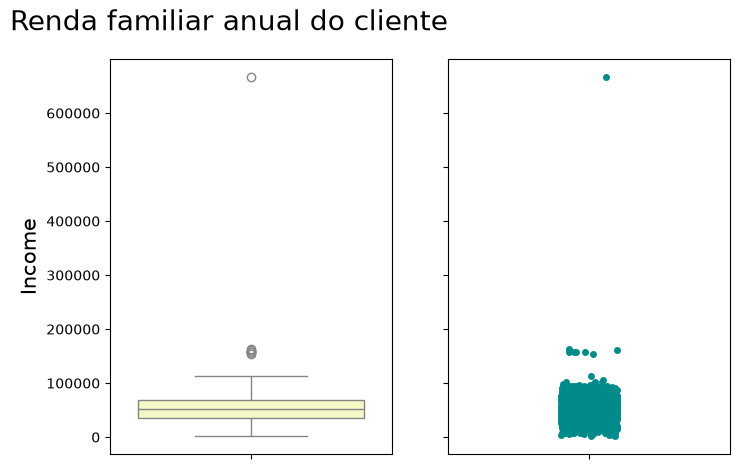

In [23]:
plot_num(people,'Income','Renda familiar anual do cliente')

📌 **Nota**
- 🔎 Há valores muito acima do restante (até 666 mil/ano), sem sentido para a base.
- ✅ **Decisão:** remover clientes com renda **acima de 200 mil/ano**.

In [24]:
people = people[people.Income < 200000]

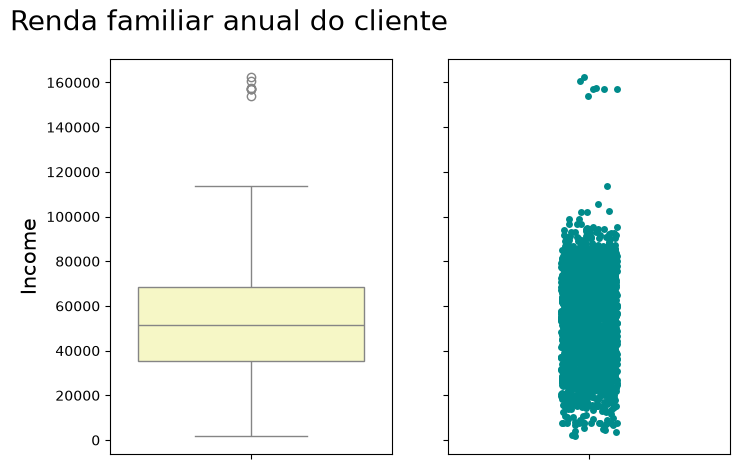

In [25]:
plot_num(people,'Income','Renda familiar anual do cliente')

📌 **Nota:** após o corte, 50% dos clientes ganham até **~50 mil/ano**.

#### Year_Birth (ano de nascimento)

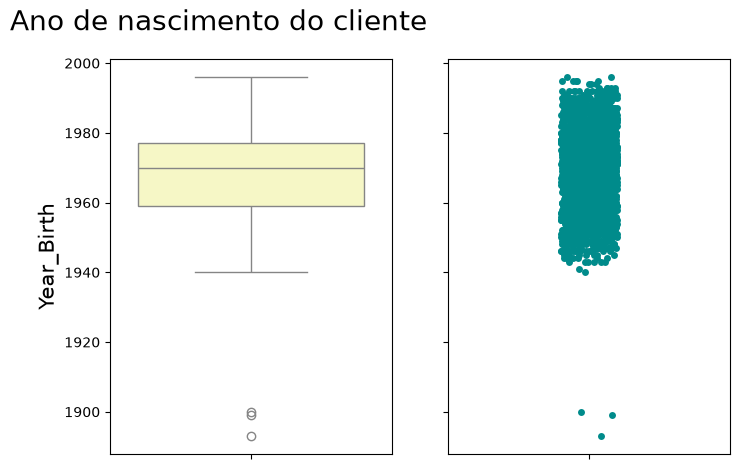

In [26]:
plot_num(people,'Year_Birth','Ano de nascimento do cliente')

📌 **Nota**
- 🔎 Três clientes nasceram antes de 1900 → erro de cadastro.
- ✅ **Decisão:** manter apenas os nascidos **após 1930**.

In [27]:
people = people[people.Year_Birth > 1930]

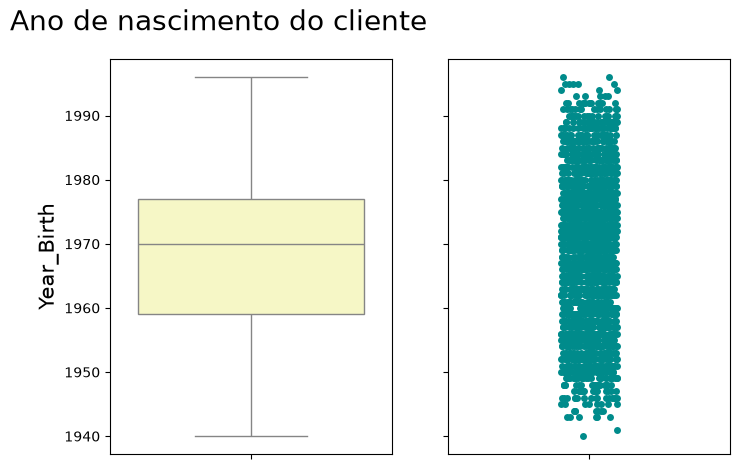

In [28]:
plot_num(people,'Year_Birth','Ano de nascimento do cliente')

#### Gastos por categoria de produto

In [29]:
show_null(products)

,QTD,% null,Type
ID,0,0.0,int64
MntWines,0,0.0,int64
MntFruits,0,0.0,int64
MntMeatProducts,0,0.0,int64
MntFishProducts,0,0.0,int64
MntSweetProducts,0,0.0,int64
MntGoldProds,0,0.0,int64


#### MntWines (Valor gasto em vinho nos últimos 2 anos)

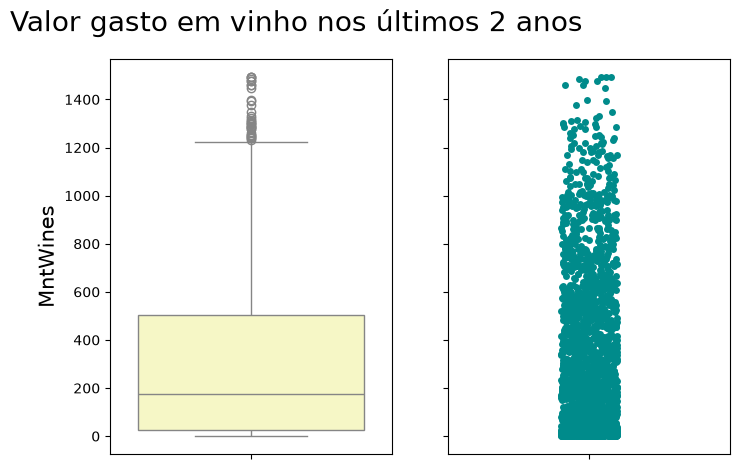

In [30]:
plot_num(products,'MntWines','Valor gasto em vinho nos últimos 2 anos')

#### MntFruits (Valor gasto com frutas nos últimos 2 anos)

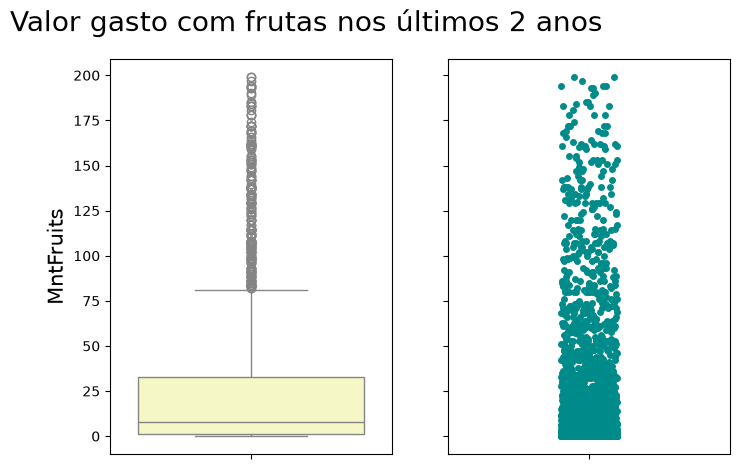

In [31]:
plot_num(products,'MntFruits','Valor gasto com frutas nos últimos 2 anos')

#### MntMeatProducts (Valor gasto com carne nos últimos 2 anos)

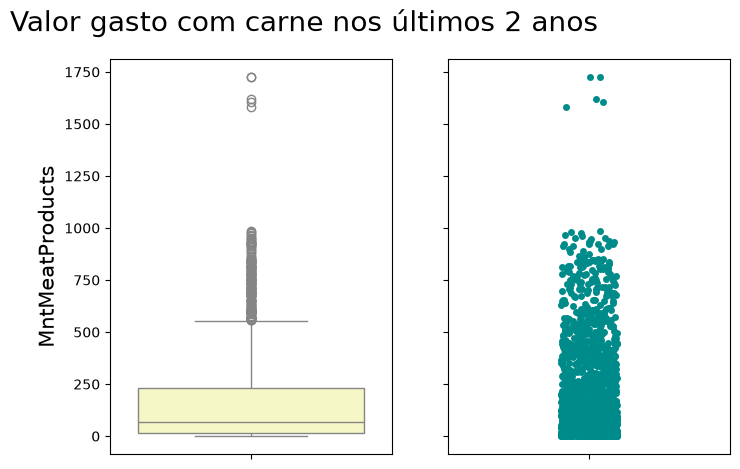

In [32]:
plot_num(products,'MntMeatProducts','Valor gasto com carne nos últimos 2 anos')

#### MntFishProducts (Valor gasto com pescado nos últimos 2 anos)

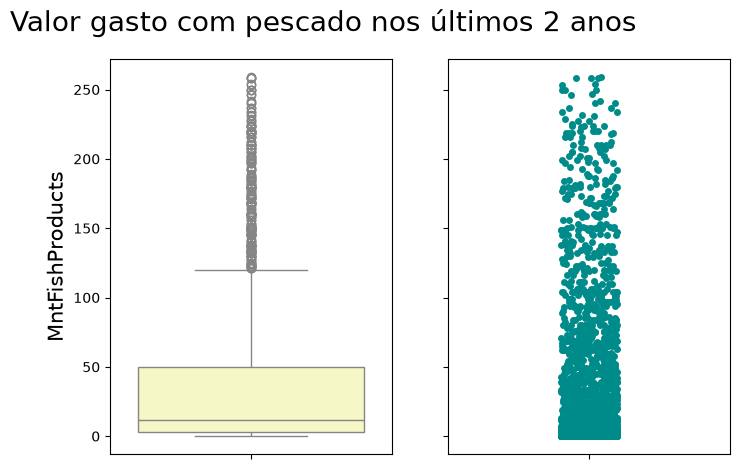

In [33]:
plot_num(products,'MntFishProducts','Valor gasto com pescado nos últimos 2 anos')

#### MntSweetProducts ( Valor gasto em doces nos últimos 2 anos)

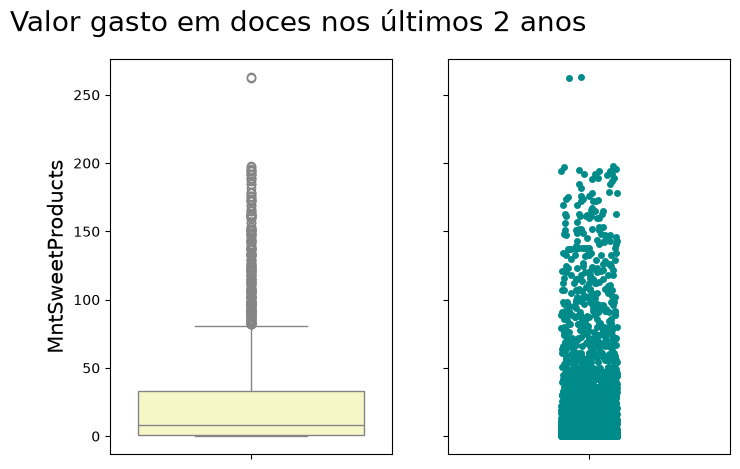

In [34]:
plot_num(products,'MntSweetProducts','Valor gasto em doces nos últimos 2 anos')

#### MntGoldProds (Valor gasto em ouro nos últimos 2 anos)

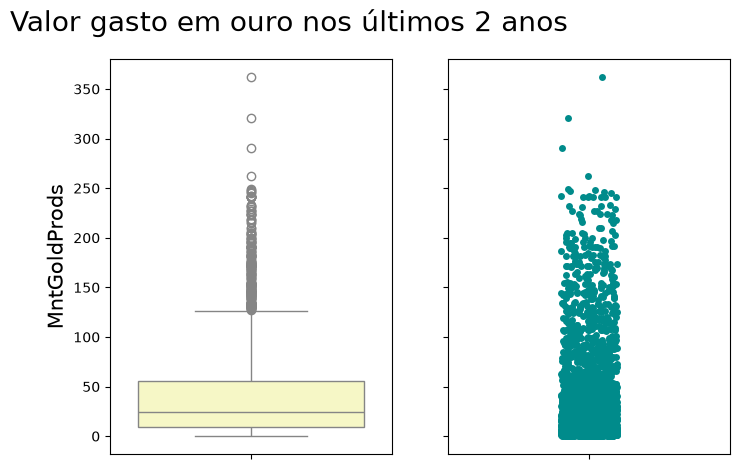

In [35]:
plot_num(products,'MntGoldProds','Valor gasto em ouro nos últimos 2 anos')

📌 **Nota**
- 🔎 Todas as categorias de produto têm muitos outliers: poucos clientes gastam muito mais que a maioria.
- ✅ **Decisão:** esses valores são **reais** (clientes de alto valor) e **não** serão removidos. No Feature Engineering vamos criar o **gasto total** e transformar cada categoria em **% do gasto**, o que reduz o efeito dos outliers.

### 2.7. Verificando o balanceamento da variável alvo

> 🚫 **Não se aplica.** Balanceamento só faz sentido quando existe uma **variável alvo** (ex.: "comprou / não comprou"). Na clusterização não há alvo: o algoritmo descobre os grupos sozinho.
>
> O equivalente aqui é verificar, na Fase 04, se os **clusters ficaram com tamanhos razoáveis** (nenhum grupo minúsculo ou gigante).

## 3 - ANÁLISE EXPLORATÓRIA DOS DADOS

A EDA ajuda a **conhecer o cliente** antes do modelo. Cada hipótese tem um gráfico e uma conclusão.

### 3.1. Criação das Hipóteses

| # | Hipótese | Tipo |
|---|---|---|
| H1 | A maioria dos clientes tem entre 30 e 50 anos | Individual |
| H2 | A maioria dos clientes possui ensino superior | Individual |
| H3 | A renda média dos clientes fica em torno de 50 mil/ano | Individual |
| H4 | A maioria dos clientes não tem filhos | Individual |
| H5 | Vinhos e carnes concentram a maior parte das vendas | Individual |
| H6 | As campanhas de promoção melhoraram ao longo do tempo | Individual |
| H7 | A maioria dos clientes gasta pouco | Individual |
| H8 | Clientes com maior renda gastam mais | Combinada |
| H9 | Clientes com filhos gastam menos | Combinada |

#### Preparação da base para a EDA

Criamos uma cópia da base com variáveis auxiliares (idade, nº de filhos, gasto total e faixa etária) e removemos erros óbvios (idade ≥ 90 anos e renda ≥ 300 mil) **apenas para os gráficos**.

In [36]:
dataframe_clean = df[['Dt_Customer','Year_Birth','Teenhome','Kidhome','MntWines','MntFruits','MntMeatProducts',
                     'MntFishProducts','MntSweetProducts','MntGoldProds','Marital_Status','Education','Income',
                     'AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5']]

In [37]:
education_dict = {
    'Graduation': 'Higher education',
    'PhD': 'Higher education',
    'Master': 'Higher education',
    'Basic': 'Basic education',
    '2n Cycle': 'Basic education'
}

dataframe_clean['Education_new'] = dataframe_clean['Education'].apply(lambda x: education_dict[x])

In [38]:
# Transformando em Data
dataframe_clean.Dt_Customer = pd.to_datetime(dataframe_clean.Dt_Customer, dayfirst=True)

In [39]:
# Age column
current_year = dataframe_clean['Dt_Customer'].max().year
dataframe_clean['Age'] = dataframe_clean['Year_Birth'].apply(lambda x: current_year-x)

# Children column
dataframe_clean['Children'] = dataframe_clean['Kidhome'] + dataframe_clean['Teenhome']

# TotalMembers column
dataframe_clean['TotalMembers'] = dataframe_clean['Children'] \
+ dataframe_clean['Marital_Status'].replace({'Single': 1, 'Together':2,'Married':2,'Divorced':1,'Widow':1,
                                                 'Absurd':1,'Alone':1,'YOLO': 1})

# TotalSpent
dataframe_clean['TotalSpent'] = dataframe_clean['MntWines'] + dataframe_clean['MntFruits'] \
+ dataframe_clean['MntMeatProducts']+ dataframe_clean['MntFishProducts'] + dataframe_clean['MntSweetProducts']\
+ dataframe_clean['MntGoldProds']

In [40]:
# Age less than 90
dataframe_clean = dataframe_clean[dataframe_clean['Age'] < 90]

# Income less than 300k
dataframe_clean = dataframe_clean[dataframe_clean['Income'] < 300000]

In [41]:
# Overwrite the dataframe_clean to data
data = dataframe_clean.copy()

# Creating age groups
def group_ages(age):
    if age < 20:
        return 18
    elif age < 30:
        return 20
    elif age < 40:
        return 30
    elif age < 50:
        return 40
    elif age < 60:
        return 50
    elif age < 70:
        return 60
    return 70

data['group_age'] = data['Age'].apply(group_ages)

### 3.2. Hipóteses Individuais (colunas isoladas)

#### H1 – A maioria dos clientes tem entre 30 e 50 anos

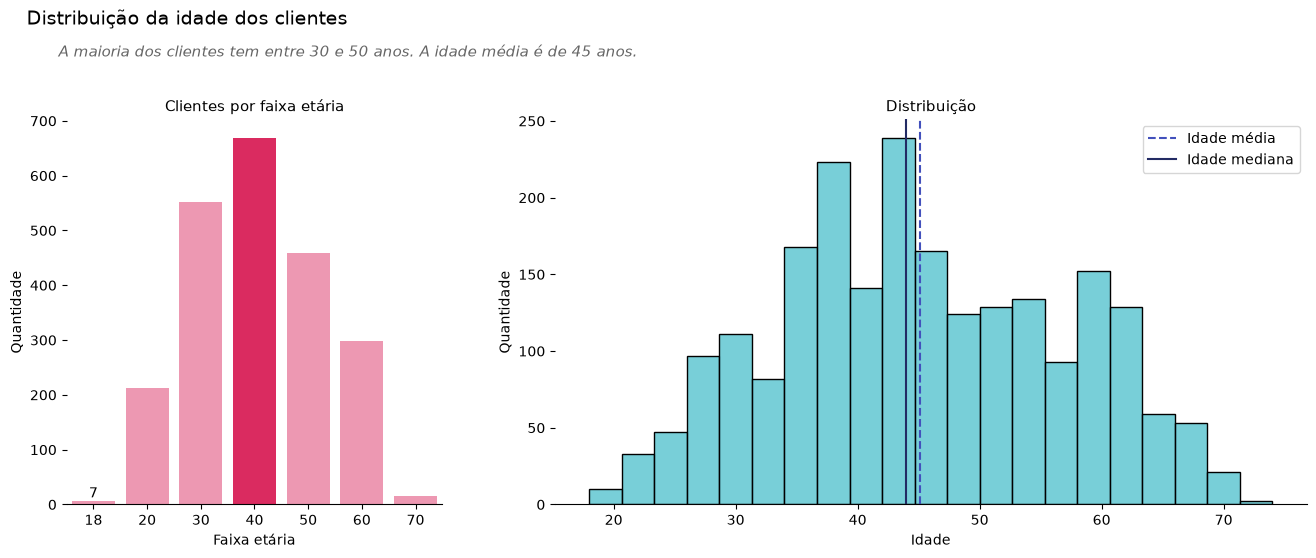

In [42]:
plot_data(df=data, 
          feature='Age', 
          titulo='Distribuição da idade dos clientes', 
          subtitulo='A maioria dos clientes tem entre 30 e 50 anos. A idade média é de 45 anos.', 
          cor=['#FB8AAC', '#FB8AAC', '#FB8AAC', '#F70E54', '#FB8AAC', '#FB8AAC', '#FB8AAC'], 
          plot_type='histogram2')

✅ **Verdadeira.** **55%** dos clientes têm entre 30 e 50 anos. A idade média é de **45 anos** (mediana de 44), e a distribuição se aproxima de uma curva normal.

#### H2 – A maioria dos clientes possui ensino superior

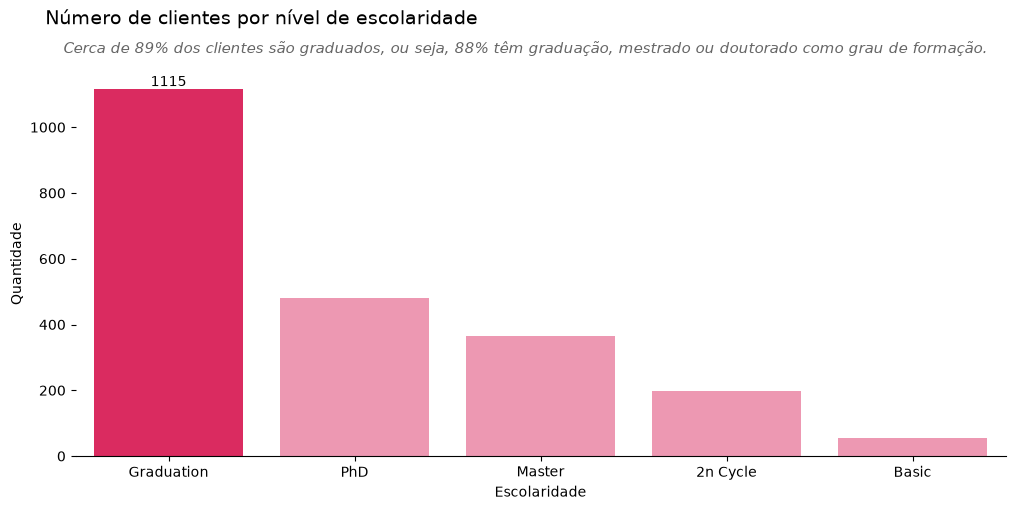

In [43]:
plot_data(df=data, 
          feature='Education', 
          titulo='Número de clientes por nível de escolaridade', 
          subtitulo='Cerca de 89% dos clientes são graduados, ou seja, 88% têm graduação, mestrado ou doutorado como grau de formação.', 
          cor=['#F70E54','#FB8AAC','#FB8AAC','#FB8AAC','#FB8AAC'], 
          plot_type='histogram1')

✅ **Verdadeira.** Cerca de **89%** têm graduação, mestrado ou doutorado, o que é coerente com a idade média de 45 anos (tempo para investir nos estudos).

#### H3 – A renda média dos clientes fica em torno de 50 mil/ano

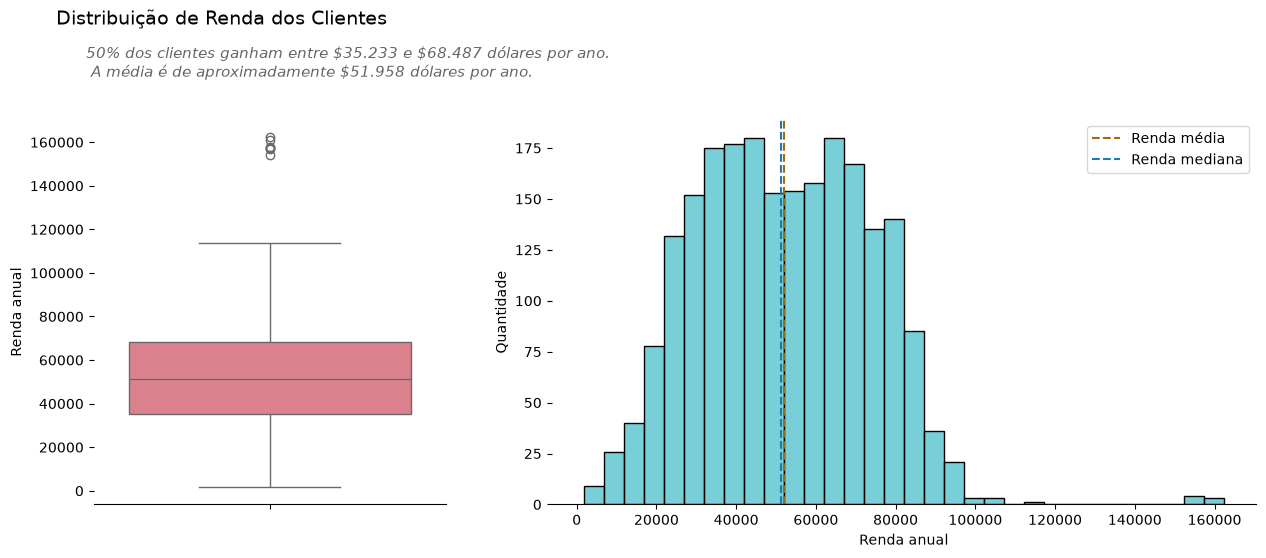

In [44]:
plot_data(df=data, 
          feature='Income', 
          titulo='Distribuição de Renda dos Clientes', 
          subtitulo= '50% dos clientes ganham entre \$35.233 e \$68.487 dólares por ano.\
  \n A média é de aproximadamente \$51.958 dólares por ano.', 
          cor='', 
          plot_type='boxhist')

✅ **Verdadeira.** Renda média de **US$ 51.958/ano**, e 50% dos clientes ganham entre **US$ 35.233 e US$ 68.487**. Há poucos clientes com renda muito alta (outliers).

#### H4 – A maioria dos clientes não tem filhos

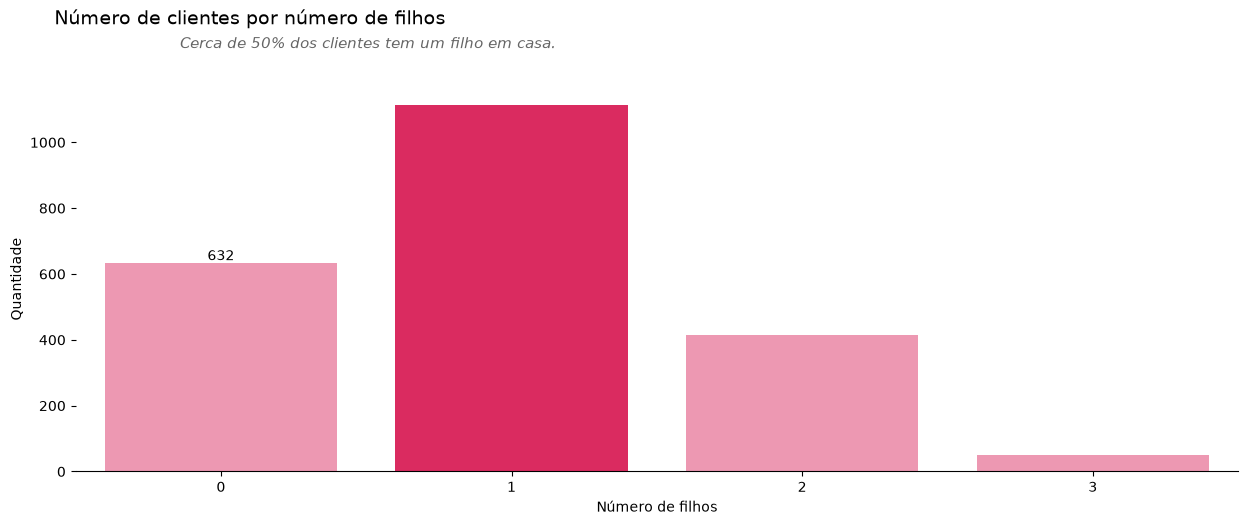

In [45]:
plot_data(df=data, 
          feature='Children', 
          titulo='Número de clientes por número de filhos', 
          subtitulo='Cerca de 50% dos clientes tem um filho em casa.', 
          cor=['#FB8AAC','#F70E54','#FB8AAC','#FB8AAC'], 
          plot_type='histogram')

❌ **Falsa.** Apenas **28,6%** não têm filhos. **50,4%** têm 1 filho, **18,8%** têm 2 e **2,3%** têm 3.

#### H5 – Vinhos e carnes concentram a maior parte das vendas

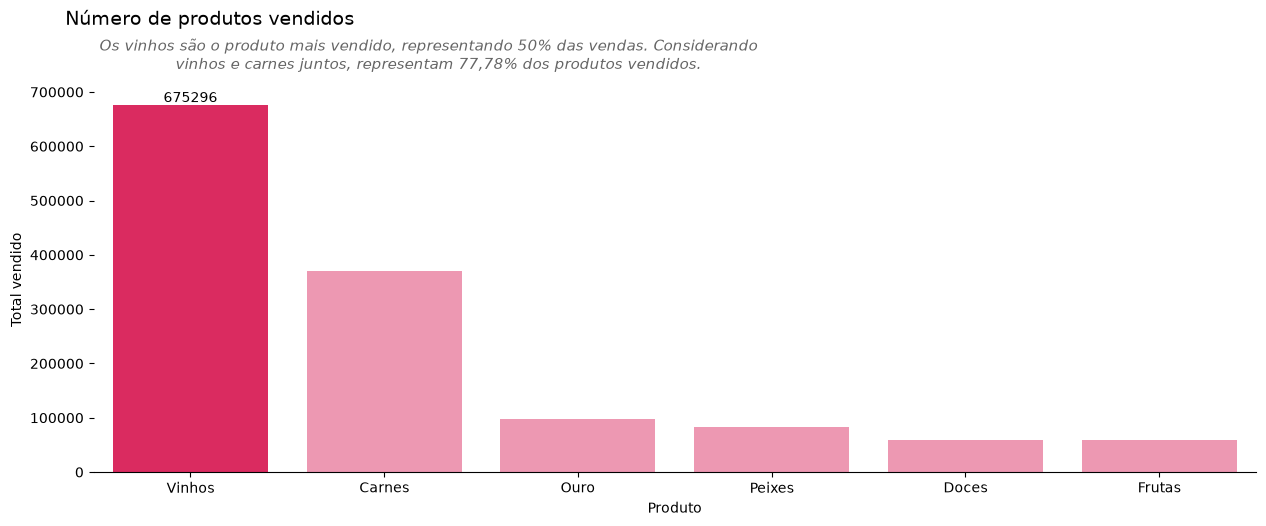

In [46]:
plot_data(df=data, 
          feature='', 
          titulo='Número de produtos vendidos', 
          subtitulo='Os vinhos são o produto mais vendido, representando 50% das vendas. Considerando \n \
  vinhos e carnes juntos, representam 77,78% dos produtos vendidos.', 
          cor=['#F70E54','#FB8AAC','#FB8AAC','#FB8AAC','#FB8AAC','#FB8AAC'], 
          plot_type='histogram3')

✅ **Verdadeira.** Vinhos representam **50%** das vendas, e vinhos + carnes somam **77,8%**. Isso sugere uma loja com foco nessas duas categorias.

#### H6 – As campanhas de promoção melhoraram ao longo do tempo

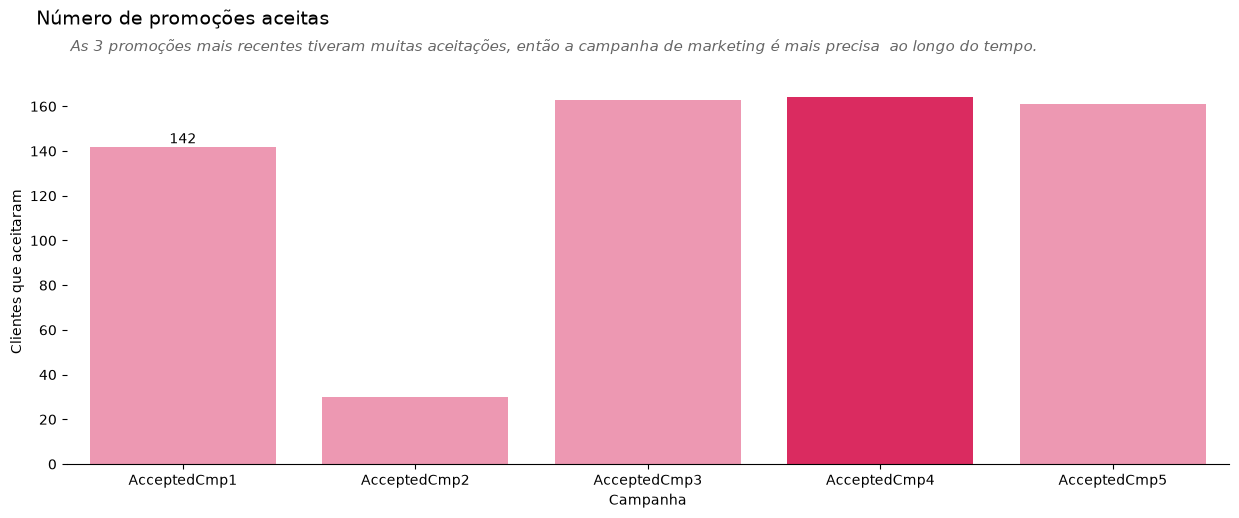

In [47]:
plot_data(df=data, 
          feature=['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5'], 
          titulo='Número de promoções aceitas', 
          subtitulo='As 3 promoções mais recentes tiveram muitas aceitações, então a campanha de marketing é mais precisa\
  ao longo do tempo.', 
          cor=['#FB8AAC','#FB8AAC','#FB8AAC','#F70E54','#FB8AAC'], 
          plot_type='histogram4')

⚠️ **Parcialmente verdadeira.** A 2ª campanha foi um fracasso (pior que a 1ª), mas a 3ª, a 4ª e a 5ª tiveram boa aceitação. O marketing **aprendeu** e melhorou as campanhas.

#### H7 – A maioria dos clientes gasta pouco

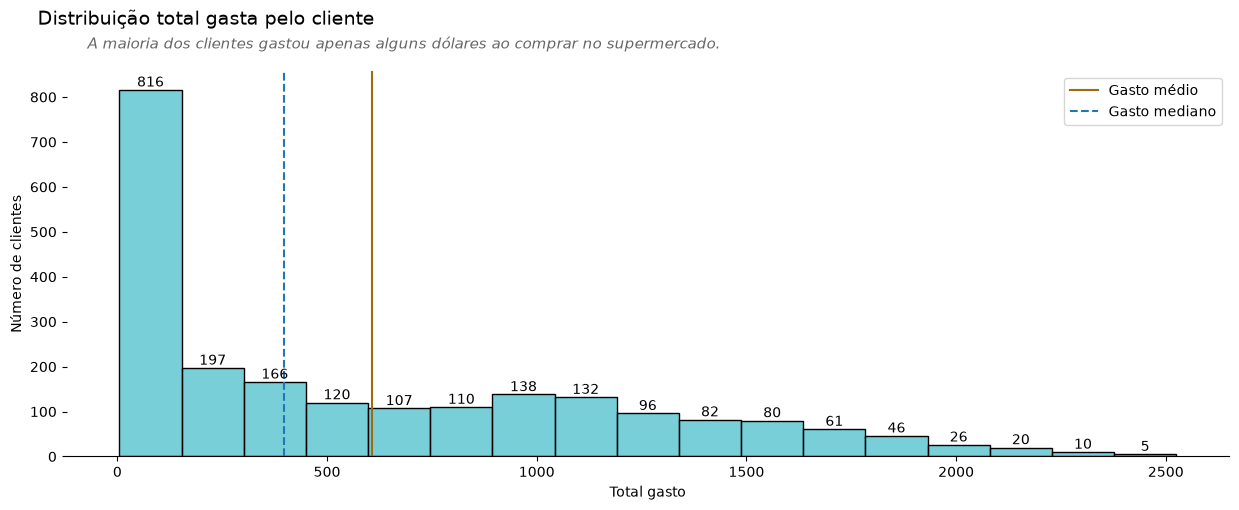

In [48]:
plot_data(df=data, 
          feature='TotalSpent', 
          titulo='Distribuição total gasta pelo cliente', 
          subtitulo='A maioria dos clientes gastou apenas alguns dólares ao comprar no supermercado.', 
          cor=['#E8E8E8','#51cedb','#E8E8E8','#E8E8E8'], 
          plot_type='histogram5')

✅ **Verdadeira.** A distribuição se concentra nos valores baixos: **50% dos clientes gastaram até US$ 397** em 2 anos.

### 3.3. Hipóteses Combinadas (entre colunas)

#### H8 – Clientes com maior renda gastam mais

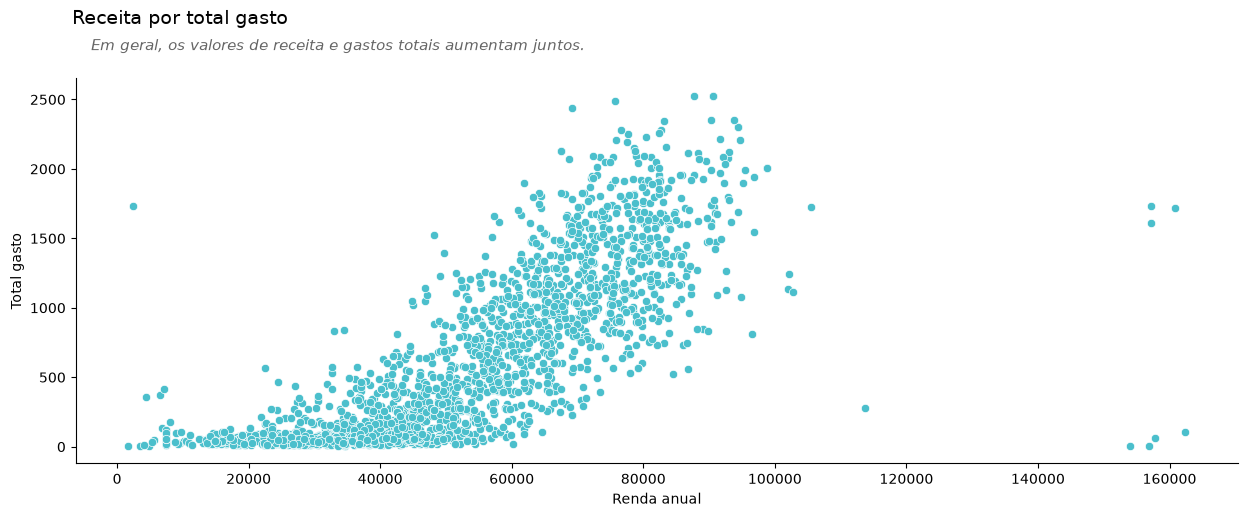

In [49]:
plot_data(df=data, 
          feature='Income', 
          titulo='Receita por total gasto', 
          subtitulo='Em geral, os valores de receita e gastos totais aumentam juntos.', 
          cor='', 
          plot_type='correlacao')

✅ **Verdadeira.** Renda e gasto crescem juntos (correlação de **0,79**), principalmente acima de **US$ 60 mil/ano**. Há poucos casos de renda alta com gasto baixo.

#### H9 – Clientes com filhos gastam menos

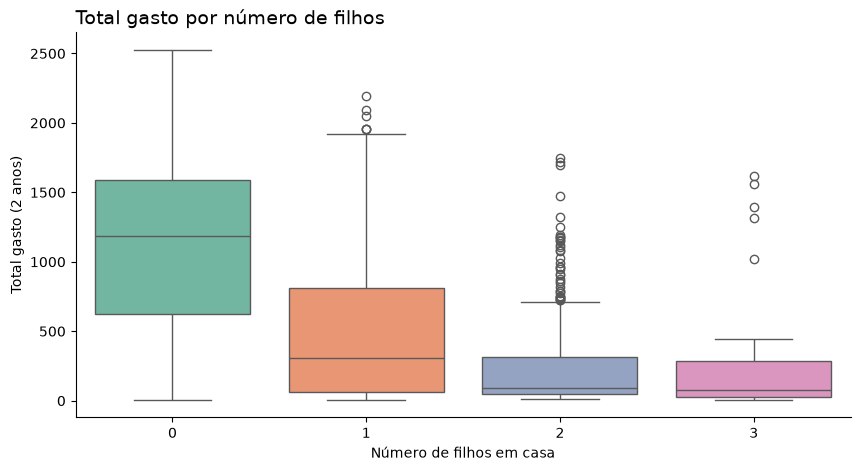

In [50]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=data, x='Children', y='TotalSpent', palette='Set2')
plt.title('Total gasto por número de filhos', fontsize=14, loc='left')
plt.xlabel('Número de filhos em casa')
plt.ylabel('Total gasto (2 anos)')
sns.despine()
plt.show()

✅ **Verdadeira.** O gasto cai bastante conforme aumenta o número de filhos:

| Filhos em casa | Gasto mediano (2 anos) |
|---|---|
| 0 | US$ 1.188 |
| 1 | US$ 308 |
| 2 | US$ 94 |
| 3 | US$ 80 |

### 3.4. Resumo das Hipóteses

| # | Hipótese | Resultado | Evidência |
|---|---|---|---|
| H1 | Maioria entre 30 e 50 anos | ✅ Verdadeira | 55% nessa faixa; idade média de 45 anos |
| H2 | Maioria com ensino superior | ✅ Verdadeira | ~89% graduados |
| H3 | Renda média de ~50 mil | ✅ Verdadeira | Média de US$ 51.958 |
| H4 | Maioria sem filhos | ❌ Falsa | 71% têm ao menos 1 filho |
| H5 | Vinhos e carnes dominam | ✅ Verdadeira | 77,8% das vendas |
| H6 | Campanhas melhoraram | ⚠️ Parcial | A 2ª campanha foi a pior |
| H7 | Maioria gasta pouco | ✅ Verdadeira | Mediana de US$ 397 |
| H8 | Mais renda → mais gasto | ✅ Verdadeira | Correlação de 0,79 |
| H9 | Com filhos → menos gasto | ✅ Verdadeira | Mediana cai de US$ 1.188 (sem filhos) para US$ 94 (2 filhos) |

> 💡 **Para o modelo:** renda, gasto total, filhos e resposta a campanhas parecem separar bem os clientes e serão variáveis importantes na clusterização.

## 4 - FEATURE ENGINEERING — (engenharia de atributos)

Aqui transformamos as colunas originais em variáveis **mais úteis para o modelo**. Resumo do que é feito em cada bloco:

| Bloco | Transformação | Por quê |
|---|---|---|
| People | `Education` → escala de 0 a 4 | É uma categoria **ordinal** (tem hierarquia) |
| People | `Marital_Status` agrupado em 4 categorias | Categorias raras ou sem sentido (YOLO, Absurd, Alone) |
| People | `ChildrenHome` = `Kidhome` + `Teenhome` | Simplifica: total de filhos em casa |
| People | `LifeTime` = meses desde o cadastro | Tempo de relacionamento com a empresa |
| People | Remoção de `Complain` | Apenas 20 clientes reclamaram |
| Products | `TotalAmountSpent` + categorias em % do gasto | Separa **quanto** gasta de **no que** gasta |
| Promotion | `AcceptedCmp` = soma das campanhas aceitas | 6 colunas viram 1 |
| Place | `TotalPurchases` + canais em % das compras | Separa **quanto** compra de **onde** compra |

### 4.1. Bloco People (perfil do cliente)

#### Education (Nível de educação do cliente)

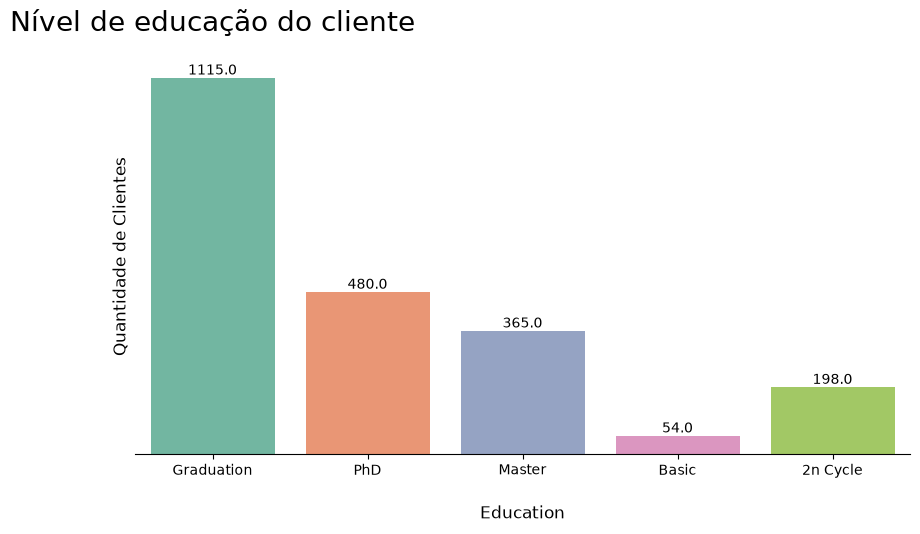

In [51]:
plot_cat(people,'Education','Nível de educação do cliente')

📌 **Nota**
- 🔎 `Education` é **ordinal**: existe uma ordem entre os níveis.
- ✅ **Decisão:** substituir por números que respeitam a hierarquia:

| Nível | Valor |
|---|---|
| Basic | 0 |
| 2n Cycle | 1 |
| Graduation | 2 |
| Master | 3 |
| PhD | 4 |

In [52]:
people.Education = people.Education.apply(lambda x: 0 if x=='Basic' 
                       else(1 if x=='2n Cycle' 
                            else(2 if x=='Graduation' 
                                 else(3 if x =='Master' 
                                      else(4 if x=='PhD' else None)))))

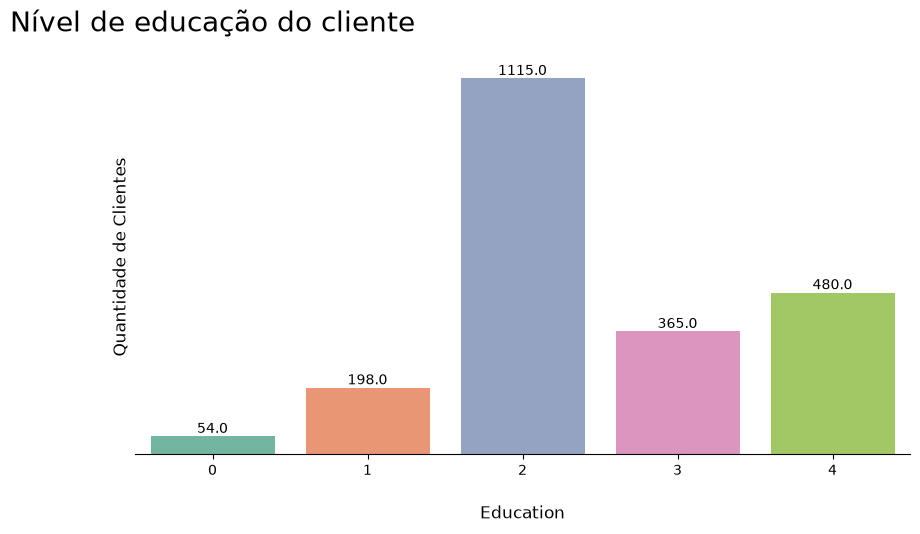

In [53]:
plot_cat(people,'Education','Nível de educação do cliente')

#### Marital_Status (estado civil)

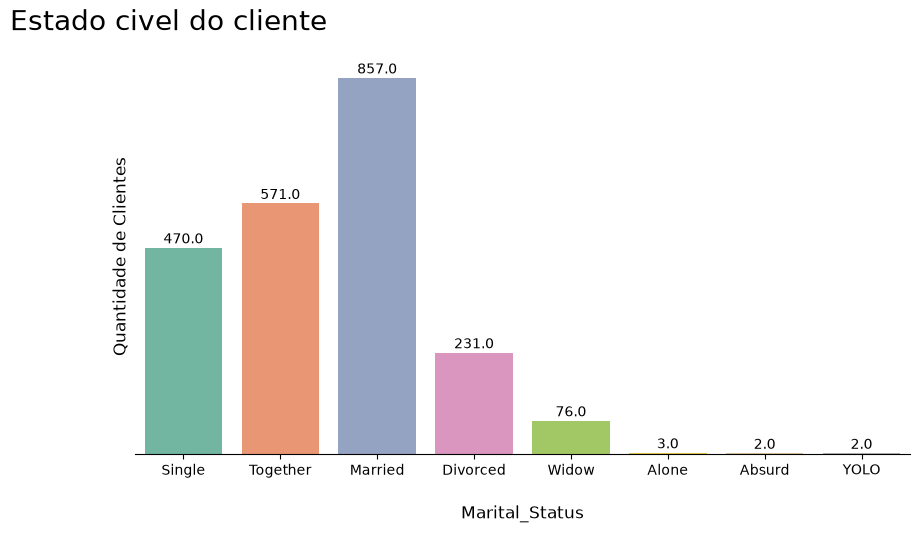

In [54]:
plot_cat(people,'Marital_Status','Estado civel do cliente')

📌 **Nota**

| Categoria | Significado | Decisão |
|---|---|---|
| Single | Solteiro | Mantém |
| Together | Mora junto | Mantém |
| Married | Casado | → Together |
| Divorced | Divorciado | Mantém |
| Widow | Viúvo | Mantém |
| Alone | Sozinho | → Single |
| YOLO | Resposta informal ("só se vive uma vez") | → Single |
| Absurd | Resposta sem sentido | Remove |

In [55]:
people = people[people.Marital_Status != 'Absurd']

In [56]:
people.Marital_Status = people.Marital_Status.apply(lambda x: 'Single' if x=='Alone' 
                                                    else('Single' if x =='YOLO' 
                                                         else ('Together' if x == 'Married'
                                                              else x)))

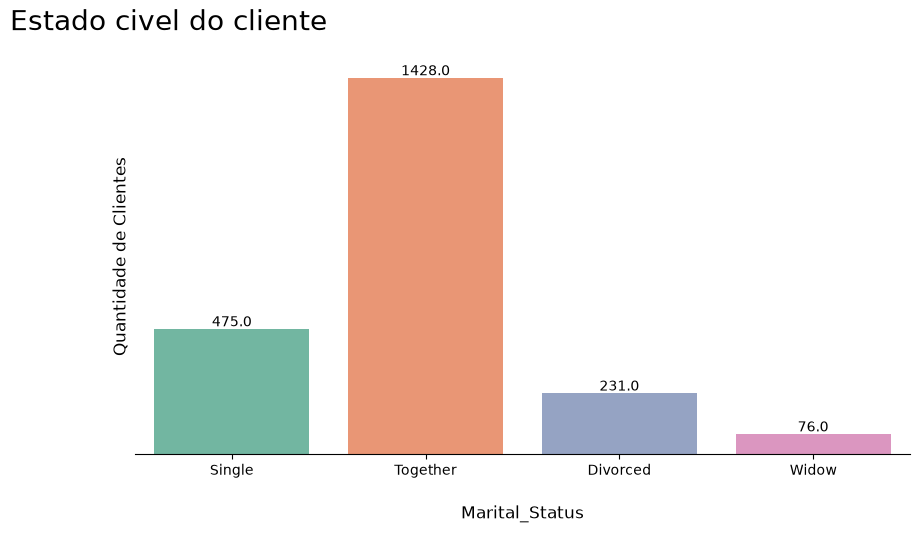

In [57]:
plot_cat(people,'Marital_Status','Estado civel do cliente')

📌 **Nota**
- 🔎 `Marital_Status` é **nominal** (não há ordem entre as categorias), então **não** podemos trocar por 0, 1, 2…
- ✅ **Decisão:** usar `get_dummies` (One-Hot Encoding) na Fase 03, criando uma coluna 0/1 para cada categoria.

#### Kidhome (Número de crianças dentro da casa do cliente)

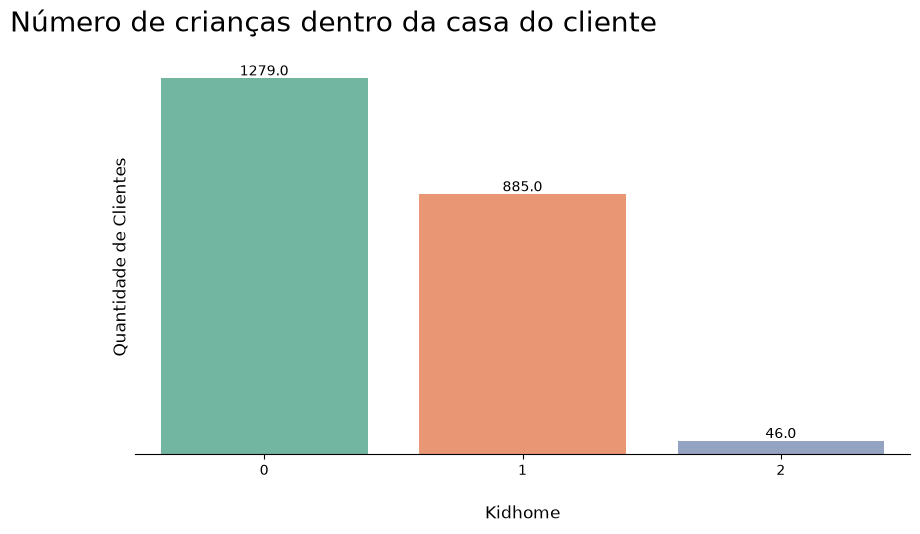

In [58]:
plot_cat(people,'Kidhome','Número de crianças dentro da casa do cliente')

#### Teenhome ( Número de adolescentes dentro da casa do cliente)

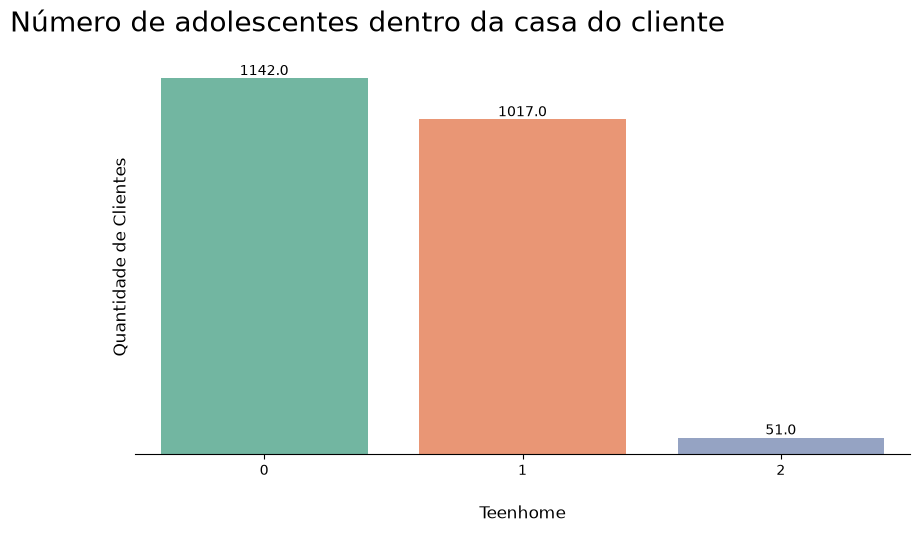

In [59]:
plot_cat(people,'Teenhome','Número de adolescentes dentro da casa do cliente')

📌 **Nota**
- 🔎 Poucos clientes têm 2 crianças ou 2 adolescentes em casa (ex.: 51 com 2 adolescentes).
- ✅ **Decisão:** para o negócio, o que importa é o **total de filhos em casa**. Vamos somar as duas colunas em `ChildrenHome` e remover as originais.

#### ChildrenHome (Quantidade de crianças dentro da casa do cliente)

In [60]:
people['ChildrenHome'] = people.Kidhome + people.Teenhome

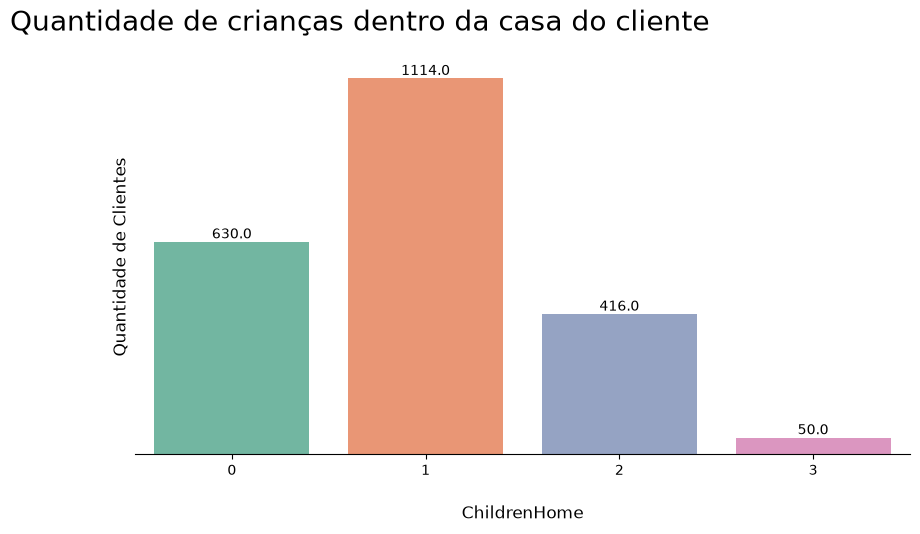

In [61]:
plot_cat(people,'ChildrenHome','Quantidade de crianças dentro da casa do cliente')

In [62]:
people.drop(columns=['Kidhome','Teenhome'],inplace=True)

In [63]:
people.head()

,ID,Year_Birth,Education,Marital_Status,Income,Dt_Customer,Recency,Complain,ChildrenHome
0,5524,1957,2,Single,58138.0,04-09-2012,58,0,0
1,2174,1954,2,Single,46344.0,08-03-2014,38,0,2
2,4141,1965,2,Together,71613.0,21-08-2013,26,0,0
3,6182,1984,2,Together,26646.0,10-02-2014,26,0,1
4,5324,1981,4,Together,58293.0,19-01-2014,94,0,1


#### Dt_Customer (Data de cadastro do cliente na empresa)

In [64]:
people.dtypes

ID                  int64
Year_Birth          int64
Education           int64
Marital_Status        str
Income            float64
Dt_Customer           str
Recency             int64
Complain            int64
ChildrenHome        int64
dtype: object

In [65]:
# Transformando em Data
people.Dt_Customer = pd.to_datetime(people.Dt_Customer, dayfirst=True)

In [66]:
people.dtypes

ID                         int64
Year_Birth                 int64
Education                  int64
Marital_Status               str
Income                   float64
Dt_Customer       datetime64[us]
Recency                    int64
Complain                   int64
ChildrenHome               int64
dtype: object

In [67]:
people.Dt_Customer.min()

Timestamp('2012-07-30 00:00:00')

In [68]:
people.Dt_Customer.max()

Timestamp('2014-06-29 00:00:00')

📌 **Nota – Como calcular o tempo de cliente (`LifeTime`)?**
- 🔎 O último cadastro é de **29/06/2014**, mas não sabemos **quando** a base foi extraída.
- 💡 Pista: `Recency` = dias desde a última compra. Então a data de referência da base é, no mínimo, o **maior valor de `Dt_Customer` + `Recency`**.
- ✅ **Decisão:** calcular essa data (célula abaixo) e usá-la como referência: `LifeTime` = meses entre o cadastro e **05/10/2014**.

In [69]:
(people['Dt_Customer'] + pd.to_timedelta(people['Recency'], unit='d')).max()

Timestamp('2014-10-04 00:00:00')

In [70]:
people['LifeTime'] = (pd.to_datetime('2014-10-05') - people['Dt_Customer']).dt.days/30

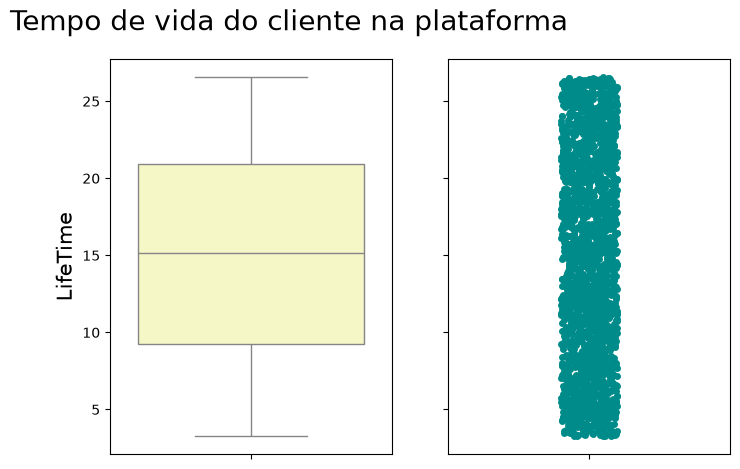

In [71]:
plot_num(people, 'LifeTime', 'Tempo de vida do cliente na plataforma')

In [72]:
people.drop(columns=['Dt_Customer'],inplace=True)

#### Recency (Número de dias desde a última compra do usuário)

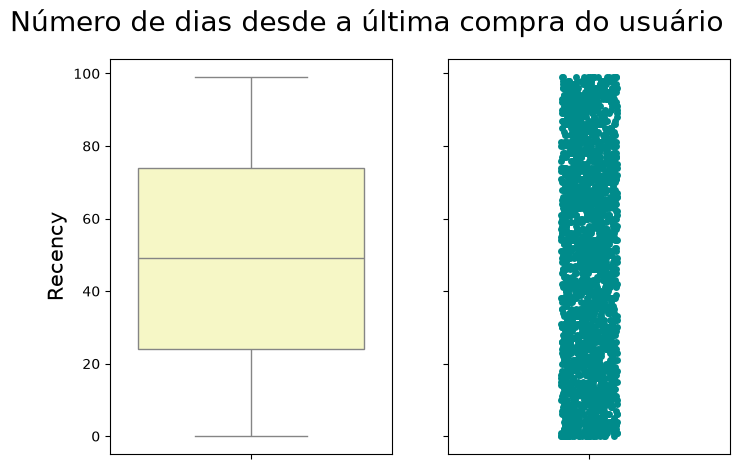

In [73]:
plot_num(people,'Recency','Número de dias desde a última compra do usuário')

#### Complain (Nível de reclamação dos clientes nos últimos dois anos)

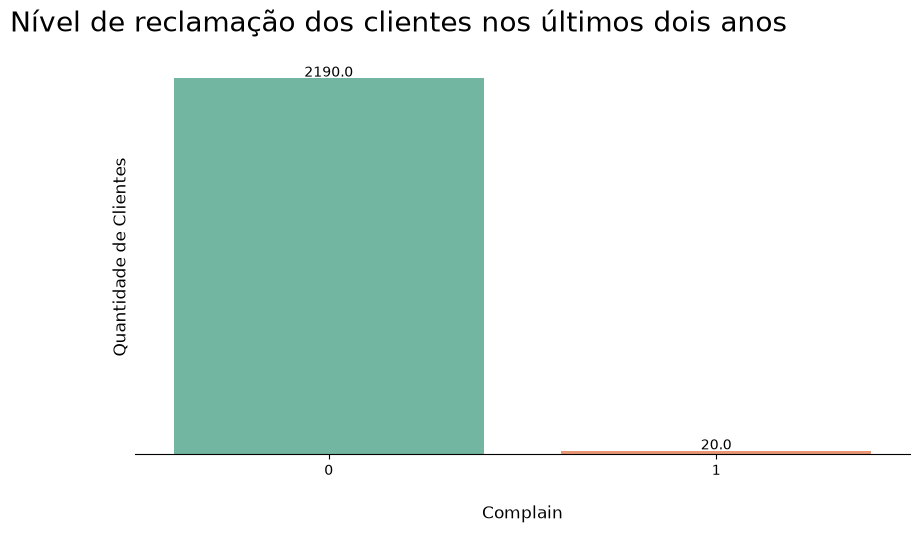

In [74]:
plot_cat(people,'Complain','Nível de reclamação dos clientes nos últimos dois anos')

📌 **Nota**
- 🔎 Apenas **20 clientes** reclamaram. A coluna quase não varia e não ajuda a separar grupos.
- ✅ **Decisão:** remover `Complain`.

In [75]:
people.drop(columns=['Complain'], inplace=True)

In [76]:
people.head()

,ID,Year_Birth,Education,Marital_Status,Income,Recency,ChildrenHome,LifeTime
0,5524,1957,2,Single,58138.0,58,0,25.366667
1,2174,1954,2,Single,46344.0,38,2,7.033333
2,4141,1965,2,Together,71613.0,26,0,13.666667
3,6182,1984,2,Together,26646.0,26,1,7.900000
4,5324,1981,4,Together,58293.0,94,1,8.633333


### 4.2. Bloco Products (gastos por categoria)

In [77]:
products['TotalAmountSpent'] = products.MntFishProducts + products.MntFruits + products.MntGoldProds \
+ products.MntMeatProducts + products.MntSweetProducts + products.MntWines

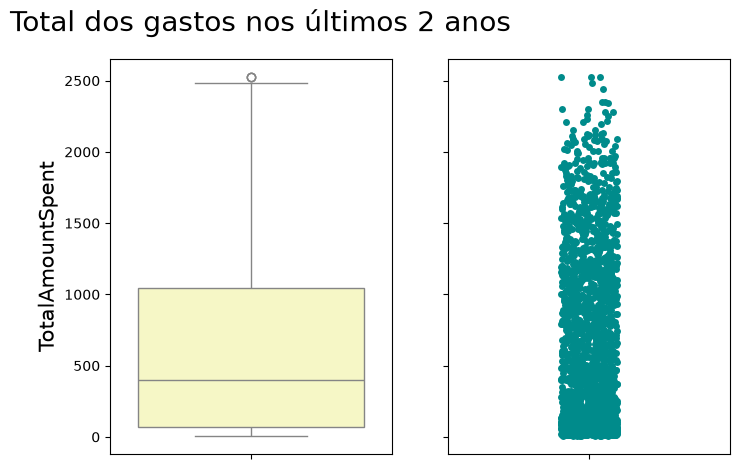

In [78]:
plot_num(products,'TotalAmountSpent','Total dos gastos nos últimos 2 anos')

📌 **Nota**
- 🔎 O gasto total tem bem menos outliers que as categorias isoladas (cerca de 3).
- ✅ **Decisão:** manter `TotalAmountSpent` (**quanto** o cliente gasta) e transformar cada categoria em **% do gasto total** (**no que** ele gasta). Assim, quem gasta 100 com vinho de um total de 200 (50%) fica parecido com quem gasta 1.000 de um total de 2.000.

In [79]:
products.MntFishProducts = products.MntFishProducts/products['TotalAmountSpent']
products.MntFruits = products.MntFruits/products['TotalAmountSpent']
products.MntGoldProds = products.MntGoldProds/products['TotalAmountSpent']
products.MntMeatProducts = products.MntMeatProducts/products['TotalAmountSpent']
products.MntSweetProducts = products.MntSweetProducts/products['TotalAmountSpent']
products.MntWines = products.MntWines/products['TotalAmountSpent']

In [80]:
products.describe()

,ID,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,TotalAmountSpent
count,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000
mean,5592.159821,0.458481,0.049505,0.249508,0.071532,0.050777,0.120196,605.798214
std,3246.662198,0.228411,0.055867,0.126633,0.077909,0.061184,0.108988,602.249288
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000
25%,2828.250000,0.289506,0.008924,0.156250,0.012571,0.008621,0.038095,68.750000
50%,5458.500000,0.457482,0.029840,0.233447,0.048193,0.033333,0.086294,396.000000
75%,8427.750000,0.639143,0.070237,0.328227,0.104703,0.070411,0.169768,1045.500000
max,11191.000000,0.963303,0.445545,0.997110,0.590909,0.945848,0.894150,2525.000000


In [81]:
products.head()

,ID,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,TotalAmountSpent
0,5524,0.392703,0.054422,0.337662,0.106370,0.054422,0.054422,1617
1,2174,0.407407,0.037037,0.222222,0.074074,0.037037,0.222222,27
2,4141,0.548969,0.063144,0.163660,0.143041,0.027062,0.054124,776
3,6182,0.207547,0.075472,0.377358,0.188679,0.056604,0.094340,53
4,5324,0.409953,0.101896,0.279621,0.109005,0.063981,0.035545,422


### 4.3. Bloco Promotion (campanhas)

In [82]:
show_null(promotion)

,QTD,% null,Type
ID,0,0.0,int64
AcceptedCmp1,0,0.0,int64
AcceptedCmp2,0,0.0,int64
AcceptedCmp3,0,0.0,int64
AcceptedCmp4,0,0.0,int64
AcceptedCmp5,0,0.0,int64
Response,0,0.0,int64


#### Criação de uma variável, para somar todas as variáveis de campanhas

In [83]:
promotion['AcceptedCmp'] = promotion.AcceptedCmp1 + promotion.AcceptedCmp2 + promotion.AcceptedCmp3 + promotion.AcceptedCmp4 + \
promotion.AcceptedCmp5 + promotion.Response

In [84]:
promotion['AcceptedCmp'].describe()

count    2240.000000
mean        0.446875
std         0.890543
min         0.000000
25%         0.000000
50%         0.000000
75%         1.000000
max         5.000000
Name: AcceptedCmp, dtype: float64

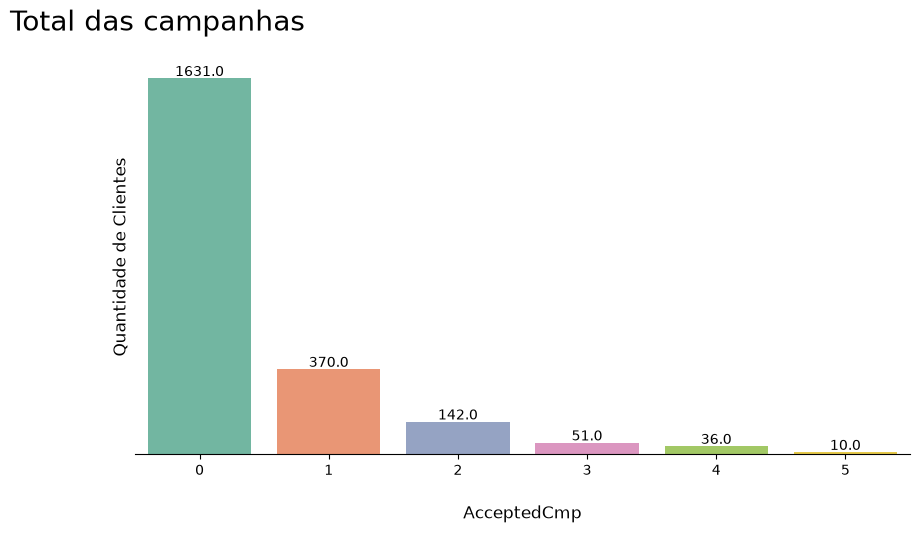

In [85]:
plot_cat(promotion,'AcceptedCmp','Total das campanhas')

📌 **Nota:** a maioria dos clientes nunca aceitou nenhuma campanha, e poucos aceitaram várias. Mantemos apenas `ID` e `AcceptedCmp`.

In [86]:
# Esse é o dataset final
promotion = promotion[['ID', 'AcceptedCmp']]

In [87]:
promotion.head()

,ID,AcceptedCmp
0,5524,1
1,2174,0
2,4141,0
3,6182,0
4,5324,0


### 4.4. Bloco Place (canais de compra)

In [88]:
show_null(place)

,QTD,% null,Type
ID,0,0.0,int64
NumWebPurchases,0,0.0,int64
NumCatalogPurchases,0,0.0,int64
NumStorePurchases,0,0.0,int64
NumDealsPurchases,0,0.0,int64
NumWebVisitsMonth,0,0.0,int64


✅ Assim como no gasto, criamos o **total de compras** por cliente (`TotalPurchases`) = site + catálogo + loja física.

In [89]:
place['TotalPurchases'] = place.NumWebPurchases + place.NumCatalogPurchases + place.NumStorePurchases

In [90]:
place.describe()

,ID,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumDealsPurchases,NumWebVisitsMonth,TotalPurchases
count,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000
mean,5592.159821,4.084821,2.662054,5.790179,2.325000,5.316518,12.537054
std,3246.662198,2.778714,2.923101,3.250958,1.932238,2.426645,7.205741
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2828.250000,2.000000,0.000000,3.000000,1.000000,3.000000,6.000000
50%,5458.500000,4.000000,2.000000,5.000000,2.000000,6.000000,12.000000
75%,8427.750000,6.000000,4.000000,8.000000,3.000000,7.000000,18.000000
max,11191.000000,27.000000,28.000000,13.000000,15.000000,20.000000,32.000000


📌 **Nota:** existem clientes com **0 compras** no total. Vamos ver quem são:

In [91]:
place[place.TotalPurchases == 0]

,ID,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumDealsPurchases,NumWebVisitsMonth,TotalPurchases
655,5555,0,0,0,0,0,0
981,3955,0,0,0,0,14,0
1245,6862,0,0,0,15,20,0
1524,11110,0,0,0,0,14,0
1846,9931,0,0,0,15,19,0
2132,11181,0,0,0,0,0,0


📌 **Nota**
- 🔎 São poucos registros, e alguns são **inconsistentes**: total de compras igual a 0, mas com até 15 compras com desconto. Compras com desconto deveriam ser uma **parte** do total.
- ✅ **Decisão:** remover os clientes sem compras.

In [92]:
place = place[place['TotalPurchases'] > 0]

✅ Agora transformamos cada canal em **% do total de compras** (mesma lógica dos produtos): `NumWebPurchases`, `NumCatalogPurchases`, `NumStorePurchases` e `NumDealsPurchases`.

In [93]:
place['NumWebPurchases'] = place['NumWebPurchases']/place['TotalPurchases']
place['NumCatalogPurchases'] = place['NumCatalogPurchases']/place['TotalPurchases']
place['NumStorePurchases'] = place['NumStorePurchases']/place['TotalPurchases']
place['NumDealsPurchases'] = place['NumDealsPurchases']/place['TotalPurchases']

In [94]:
place.describe()

,ID,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumDealsPurchases,NumWebVisitsMonth,TotalPurchases
count,2234.000000,2234.000000,2234.000000,2234.000000,2234.000000,2234.000000,2234.000000
mean,5585.427037,0.329874,0.164809,0.505317,0.247963,5.300806,12.570725
std,3245.168172,0.121858,0.140668,0.149485,0.356679,2.372957,7.186011
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2817.750000,0.250000,0.000000,0.401852,0.083333,3.000000,6.000000
50%,5453.500000,0.333333,0.150000,0.500000,0.200000,6.000000,12.000000
75%,8419.500000,0.400000,0.250000,0.600000,0.333333,7.000000,18.000000
max,11191.000000,1.000000,1.000000,1.000000,15.000000,20.000000,32.000000


📌 **Nota:** um percentual não pode passar de 100% (1,0), mas `NumDealsPurchases` chega a **15**. Vamos ver qual é o registro:

In [95]:
place[place.NumDealsPurchases > 1]

,ID,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumDealsPurchases,NumWebVisitsMonth,TotalPurchases
1042,10749,0.0,1.0,0.0,15.0,19,1


✅ **Decisão:** é um erro de registro. Removemos para não distorcer a clusterização.

In [96]:
place = place[place['NumDealsPurchases'] <= 1]

#### NumWebVisitsMonth (visitas ao site no último mês)

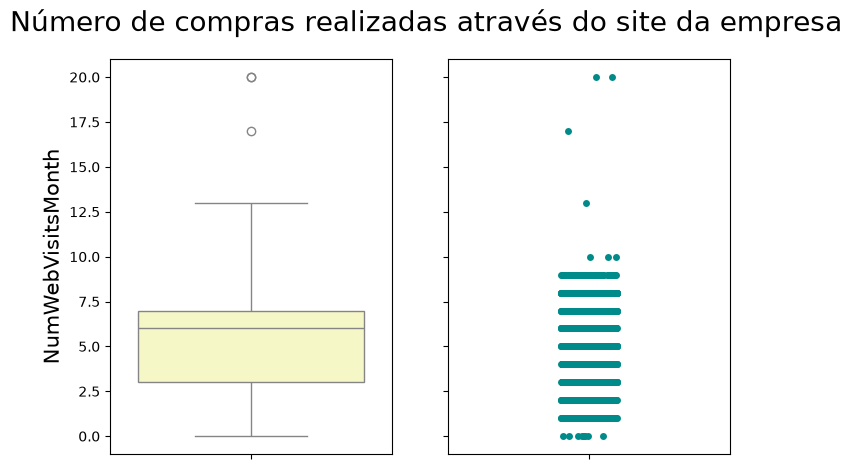

In [97]:
plot_num(place,'NumWebVisitsMonth','Número de compras realizadas através do site da empresa')

📌 **Nota**
- 🔎 Há 1 ou 2 clientes com muitas visitas ao site (outliers).
- ✅ **Decisão:** manter. São poucos e podem ser clientes reais muito engajados.

## 5 - EXPLORANDO AS CORRELAÇÕES

A correlação mostra o quanto duas variáveis **andam juntas** (de -1 a +1). Na clusterização, ela ajuda a identificar variáveis **redundantes** (que dizem a mesma coisa) e as relações mais fortes da base.

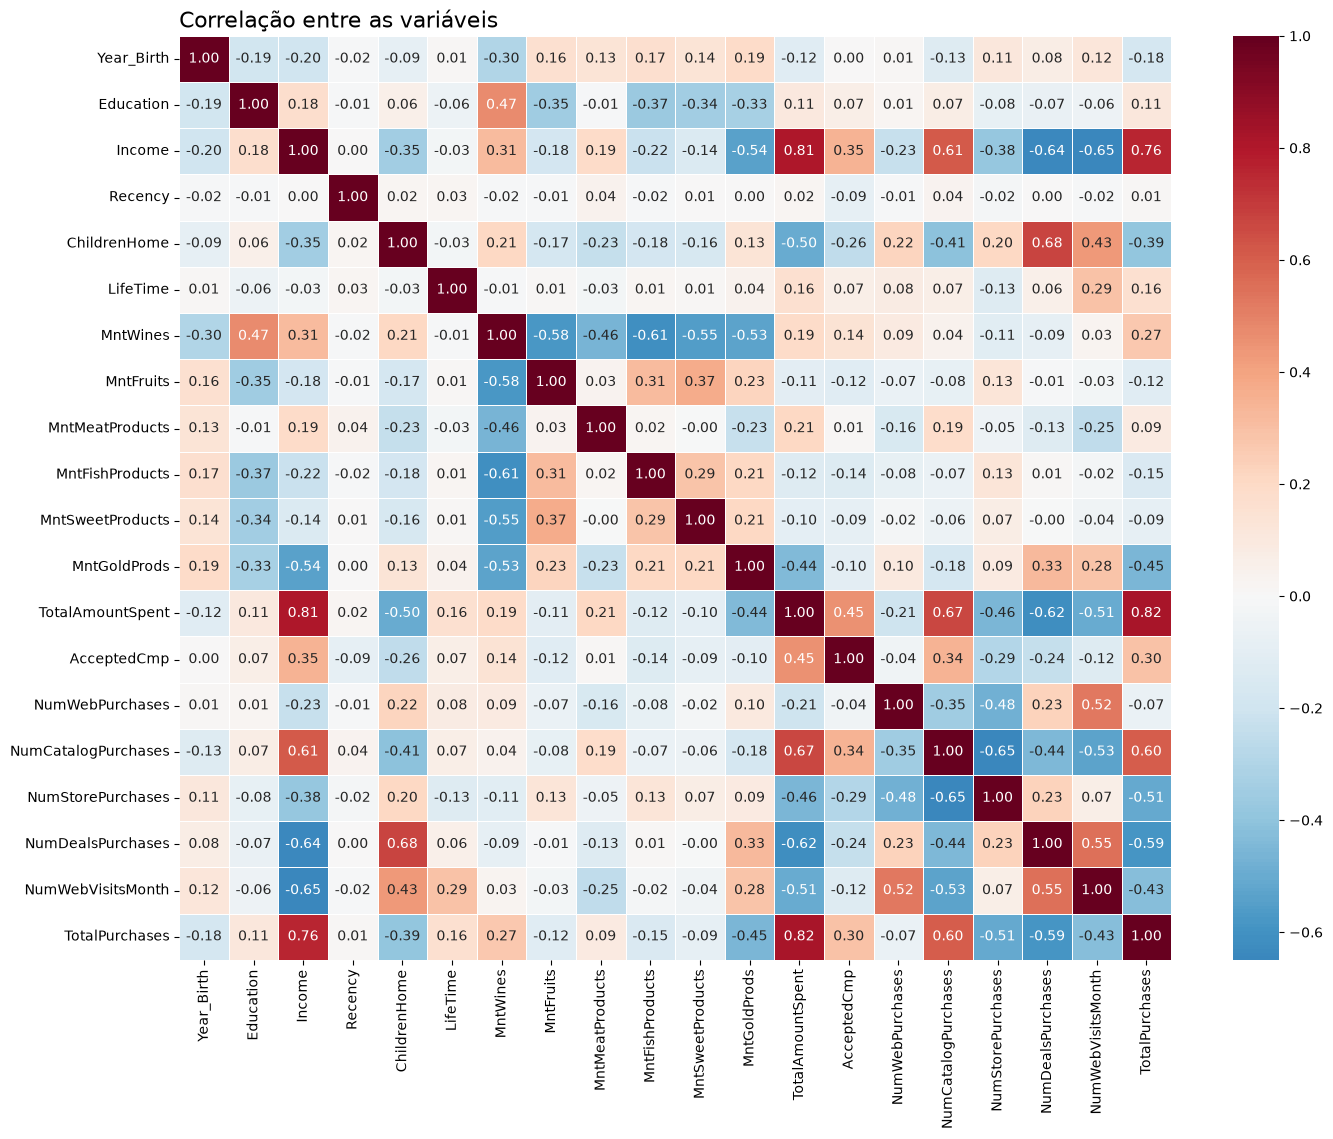

In [98]:
# Junta os 4 blocos já tratados para analisar as correlações
df_corr = reduce(lambda df1, df2: pd.merge(df1, df2, on='ID'), [people, products, promotion, place])
df_corr = df_corr.drop(columns=['ID']).select_dtypes(include='number')

plt.figure(figsize=(16, 12))
sns.heatmap(df_corr.corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, linewidths=0.5)
plt.title('Correlação entre as variáveis', fontsize=16, loc='left')
plt.show()

📌 **Nota – principais correlações**

| Par de variáveis | Correlação | Leitura |
|---|---|---|
| `TotalAmountSpent` × `TotalPurchases` | **+0,82** | Quem compra mais vezes gasta mais |
| `Income` × `TotalAmountSpent` | **+0,81** | Quem ganha mais gasta mais (confirma a H8) |
| `Income` × `TotalPurchases` | +0,76 | Renda também aumenta a frequência de compra |
| `ChildrenHome` × `NumDealsPurchases` | +0,68 | Quem tem filhos compra mais com desconto |
| `Income` × `NumWebVisitsMonth` | -0,65 | Quem ganha menos visita mais o site |
| `Income` × `NumDealsPurchases` | -0,64 | Quem ganha menos depende mais de desconto |
| `ChildrenHome` × `TotalAmountSpent` | -0,50 | Quem tem filhos gasta menos (confirma a H9) |

- 🔎 Renda, gasto e frequência de compra andam juntos: são o **eixo principal** que separa os clientes.
- ⚠️ `TotalAmountSpent` e `TotalPurchases` passam de 0,8, mas foram **mantidas**: medem coisas diferentes para o negócio (valor x frequência) e permitem separar o cliente que compra muito com ticket alto (*Premium*) do que compra muito com ticket menor (*Fiéis de alto volume*).

# FASE 03: MODELAGEM DOS DADOS

Com os dados preparados, juntamos os blocos, transformamos tudo em números na mesma escala e treinamos o **K-Means**.

## 1 - Leitura dos dados

Juntamos os 4 blocos (People, Products, Promotion e Place) pelo `ID`. Como cada bloco teve registros removidos na limpeza, o `merge` mantém apenas os clientes presentes em **todos** os blocos.

In [99]:
# Juntando Dados
df_lista = [people, products, promotion, place]

In [100]:
df_final = reduce(lambda df1, df2: pd.merge(df1, df2, on='ID'), df_lista)

In [101]:
df_final.shape

(2203, 22)

📌 **Nota:** a base final tem **2.203 clientes** (eram 2.240, ou seja, 37 foram removidos na limpeza, ~1,7%).

In [102]:
print(df_final.columns.to_list())

['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Recency', 'ChildrenHome', 'LifeTime', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'TotalAmountSpent', 'AcceptedCmp', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumDealsPurchases', 'NumWebVisitsMonth', 'TotalPurchases']


In [103]:
# Remover o ID, porque usamos ele para fazer somente o relacionamento, ele não é uma variável caracteristica do usuário
df_final.drop(columns=['ID'], inplace=True)

## 2 - Valores nulos

In [104]:
show_null(df_final)

,QTD,% null,Type
Year_Birth,0,0.0,int64
Education,0,0.0,int64
Marital_Status,0,0.0,str
Income,0,0.0,float64
Recency,0,0.0,int64
ChildrenHome,0,0.0,int64
LifeTime,0,0.0,float64
MntWines,0,0.0,float64
MntFruits,0,0.0,float64
MntMeatProducts,0,0.0,float64


✅ Nenhum valor nulo na base final.

## 3 - Transformação

`Marital_Status` é um texto **nominal**. Aplicamos **One-Hot Encoding** (`get_dummies`): cada categoria vira uma coluna 0/1.

In [105]:
df_final.head()

,Year_Birth,Education,Marital_Status,Income,Recency,ChildrenHome,LifeTime,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,TotalAmountSpent,AcceptedCmp,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumDealsPurchases,NumWebVisitsMonth,TotalPurchases
0,1957,2,Single,58138.0,58,0,25.366667,0.392703,0.054422,0.337662,0.106370,0.054422,0.054422,1617,1,0.363636,0.454545,0.181818,0.136364,7,22
1,1954,2,Single,46344.0,38,2,7.033333,0.407407,0.037037,0.222222,0.074074,0.037037,0.222222,27,0,0.250000,0.250000,0.500000,0.500000,5,4
2,1965,2,Together,71613.0,26,0,13.666667,0.548969,0.063144,0.163660,0.143041,0.027062,0.054124,776,0,0.400000,0.100000,0.500000,0.050000,4,20
3,1984,2,Together,26646.0,26,1,7.900000,0.207547,0.075472,0.377358,0.188679,0.056604,0.094340,53,0,0.333333,0.000000,0.666667,0.333333,6,6
4,1981,4,Together,58293.0,94,1,8.633333,0.409953,0.101896,0.279621,0.109005,0.063981,0.035545,422,0,0.357143,0.214286,0.428571,0.357143,5,14


In [106]:
df_final = pd.get_dummies(df_final, dtype=int)

In [107]:
df_final.head()

,Year_Birth,Education,Income,Recency,ChildrenHome,LifeTime,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,TotalAmountSpent,AcceptedCmp,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumDealsPurchases,NumWebVisitsMonth,TotalPurchases,Marital_Status_Divorced,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow
0,1957,2,58138.0,58,0,25.366667,0.392703,0.054422,0.337662,0.106370,0.054422,0.054422,1617,1,0.363636,0.454545,0.181818,0.136364,7,22,0,1,0,0
1,1954,2,46344.0,38,2,7.033333,0.407407,0.037037,0.222222,0.074074,0.037037,0.222222,27,0,0.250000,0.250000,0.500000,0.500000,5,4,0,1,0,0
2,1965,2,71613.0,26,0,13.666667,0.548969,0.063144,0.163660,0.143041,0.027062,0.054124,776,0,0.400000,0.100000,0.500000,0.050000,4,20,0,0,1,0
3,1984,2,26646.0,26,1,7.900000,0.207547,0.075472,0.377358,0.188679,0.056604,0.094340,53,0,0.333333,0.000000,0.666667,0.333333,6,6,0,0,1,0
4,1981,4,58293.0,94,1,8.633333,0.409953,0.101896,0.279621,0.109005,0.063981,0.035545,422,0,0.357143,0.214286,0.428571,0.357143,5,14,0,0,1,0


In [108]:
df_final.shape

(2203, 24)

## 4 - Pré-Processamento

### 4.1. Separação do conjunto de dados

> 🚫 **Não se aplica.** Em problemas supervisionados, separamos treino e teste para medir se o modelo **acerta previsões** em dados novos. Na clusterização não existe uma resposta certa para comparar: usamos **todos os clientes** para encontrar os grupos, e a qualidade é medida com o **Silhouette Score** e com a **interpretação de negócio** (Fase 04).

### 4.2. Balancear os dados

> 🚫 **Não se aplica.** Não há variável alvo para balancear (ver Fase 02, item 2.7).

### 4.3. Seleção de Variáveis

#### Normalização

O K-Means agrupa clientes pela **distância** entre eles. Se uma coluna está em milhares (`Income`) e outra entre 0 e 1 (percentuais), a de maior escala **domina o cálculo** sozinha. Por isso, colocamos todas as colunas **na mesma régua** (de 0 a 1) com a normalização Min-Max.

In [109]:
scaled_df = scaler(df_final)

In [110]:
scaled_df.describe()

,Year_Birth,Education,Income,Recency,ChildrenHome,LifeTime,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,TotalAmountSpent,AcceptedCmp,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumDealsPurchases,NumWebVisitsMonth,TotalPurchases,Marital_Status_Divorced,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow
count,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000
mean,0.516179,0.615070,0.309517,0.494858,0.316689,0.506590,0.477108,0.110423,0.249853,0.120857,0.053607,0.134151,0.238604,0.089877,0.330002,0.164580,0.505419,0.241032,0.265138,0.374255,0.103495,0.214707,0.647299,0.034498
std,0.208790,0.251205,0.132629,0.292626,0.249584,0.289392,0.237445,0.124819,0.126184,0.132076,0.064434,0.121894,0.239412,0.178555,0.120862,0.139301,0.148665,0.172198,0.117599,0.231731,0.304674,0.410712,0.477919,0.182547
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.339286,0.500000,0.205796,0.242424,0.000000,0.258941,0.301382,0.020003,0.156637,0.021255,0.009126,0.042521,0.024235,0.000000,0.250000,0.000000,0.400000,0.083333,0.150000,0.161290,0.000000,0.000000,0.000000,0.000000
50%,0.535714,0.500000,0.305883,0.494949,0.333333,0.509299,0.477821,0.066438,0.234010,0.081269,0.034950,0.094632,0.154946,0.000000,0.333333,0.150000,0.500000,0.200000,0.300000,0.354839,0.000000,0.000000,1.000000,0.000000
75%,0.660714,0.750000,0.412801,0.747475,0.333333,0.756795,0.666694,0.155363,0.329124,0.175066,0.074329,0.189881,0.413190,0.200000,0.400000,0.250000,0.600000,0.333333,0.350000,0.580645,0.000000,0.000000,1.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [111]:
# Guarda uma cópia SEM pesos para reproduzir o Método do Cotovelo da versão original (seção 6.1)
scaled_df_sem_pesos = scaled_df.copy()

#### Alocação de pesos

Nem toda variável tem a mesma importância para o negócio. Junto ao time de marketing, definimos **pesos**: multiplicar uma coluna por um peso maior aumenta a influência dela na distância e, portanto, na formação dos grupos.

| Variável | Peso | Motivo |
|---|---|---|
| `TotalAmountSpent` | 8 | Quanto o cliente gasta: principal critério de valor |
| `TotalPurchases` | 6 | Frequência de compra |
| `Recency`, `NumWebVisitsMonth`, `Income`, `LifeTime` | 4 | Engajamento, renda e tempo de relacionamento |
| `Year_Birth`, `ChildrenHome`, `Education` | 2 | Perfil demográfico |
| Demais variáveis | 1 | Sem peso extra |

> ⚠️ Os pesos são uma **decisão de negócio** (subjetiva). Mudar os pesos muda os grupos.

In [112]:
print(scaled_df.columns.to_list())

['Year_Birth', 'Education', 'Income', 'Recency', 'ChildrenHome', 'LifeTime', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'TotalAmountSpent', 'AcceptedCmp', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumDealsPurchases', 'NumWebVisitsMonth', 'TotalPurchases', 'Marital_Status_Divorced', 'Marital_Status_Single', 'Marital_Status_Together', 'Marital_Status_Widow']


In [113]:
print(PESOS)

scaled_df = aplicar_pesos(scaled_df, PESOS)

{'TotalAmountSpent': 8, 'TotalPurchases': 6, 'Recency': 4, 'NumWebVisitsMonth': 4, 'Income': 4, 'LifeTime': 4, 'Year_Birth': 2, 'ChildrenHome': 2, 'Education': 2}


In [114]:
scaled_df.describe()

,Year_Birth,Education,Income,Recency,ChildrenHome,LifeTime,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,TotalAmountSpent,AcceptedCmp,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumDealsPurchases,NumWebVisitsMonth,TotalPurchases,Marital_Status_Divorced,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow
count,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000
mean,1.032358,1.230141,1.238068,1.979431,0.633379,2.026362,0.477108,0.110423,0.249853,0.120857,0.053607,0.134151,1.908833,0.089877,0.330002,0.164580,0.505419,0.241032,1.060554,2.245530,0.103495,0.214707,0.647299,0.034498
std,0.417580,0.502410,0.530515,1.170504,0.499168,1.157569,0.237445,0.124819,0.126184,0.132076,0.064434,0.121894,1.915298,0.178555,0.120862,0.139301,0.148665,0.172198,0.470396,1.390384,0.304674,0.410712,0.477919,0.182547
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.678571,1.000000,0.823182,0.969697,0.000000,1.035765,0.301382,0.020003,0.156637,0.021255,0.009126,0.042521,0.193882,0.000000,0.250000,0.000000,0.400000,0.083333,0.600000,0.967742,0.000000,0.000000,0.000000,0.000000
50%,1.071429,1.000000,1.223532,1.979798,0.666667,2.037196,0.477821,0.066438,0.234010,0.081269,0.034950,0.094632,1.239571,0.000000,0.333333,0.150000,0.500000,0.200000,1.200000,2.129032,0.000000,0.000000,1.000000,0.000000
75%,1.321429,1.500000,1.651204,2.989899,0.666667,3.027182,0.666694,0.155363,0.329124,0.175066,0.074329,0.189881,3.305522,0.200000,0.400000,0.250000,0.600000,0.333333,1.400000,3.483871,0.000000,0.000000,1.000000,0.000000
max,2.000000,2.000000,4.000000,4.000000,2.000000,4.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,8.000000,1.000000,1.000000,1.000000,1.000000,1.000000,4.000000,6.000000,1.000000,1.000000,1.000000,1.000000


📌 **Nota:** após os pesos, as variáveis prioritárias passam a ter uma amplitude maior (ex.: `TotalAmountSpent` vai de 0 a 8).

## 5 - Treinamento dos Algoritmos de Machine Learning

### K-Means

O K-Means é um algoritmo **não supervisionado**: não recebe uma resposta para aprender, apenas os dados.

**Como funciona, de forma simples:**
1. Escolhemos quantos grupos queremos (**k**).
2. O algoritmo posiciona k "centros" e coloca cada cliente no centro **mais próximo** (distância Euclidiana).
3. Recalcula cada centro como a média dos seus clientes e repete até os grupos pararem de mudar.

> 💡 **Analogia:** é como organizar os convidados de uma festa em 4 mesas, colocando pessoas parecidas na mesma mesa.

O número de grupos **k = 4** foi definido pelo Método do Cotovelo no projeto original e é reavaliado na seção 6.

In [115]:
Model = KMeans(n_clusters=4, n_init=10, random_state=42)

In [116]:
# Treinamento do algoritmo k-means, para colocar cada um dos registros em um dos 4 grupos
clusters = Model.fit_predict(scaled_df)

In [117]:
clusters

array([2, 3, 0, ..., 0, 0, 3], shape=(2203,), dtype=int32)

In [118]:
df_final['cluster'] = clusters

In [119]:
# Temos clusters para cada usuário
df_final

,Year_Birth,Education,Income,Recency,ChildrenHome,LifeTime,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,TotalAmountSpent,AcceptedCmp,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumDealsPurchases,NumWebVisitsMonth,TotalPurchases,Marital_Status_Divorced,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,cluster
0,1957,2,58138.0,58,0,25.366667,0.392703,0.054422,0.337662,0.106370,0.054422,0.054422,1617,1,0.363636,0.454545,0.181818,0.136364,7,22,0,1,0,0,2
1,1954,2,46344.0,38,2,7.033333,0.407407,0.037037,0.222222,0.074074,0.037037,0.222222,27,0,0.250000,0.250000,0.500000,0.500000,5,4,0,1,0,0,3
2,1965,2,71613.0,26,0,13.666667,0.548969,0.063144,0.163660,0.143041,0.027062,0.054124,776,0,0.400000,0.100000,0.500000,0.050000,4,20,0,0,1,0,0
3,1984,2,26646.0,26,1,7.900000,0.207547,0.075472,0.377358,0.188679,0.056604,0.094340,53,0,0.333333,0.000000,0.666667,0.333333,6,6,0,0,1,0,3
4,1981,4,58293.0,94,1,8.633333,0.409953,0.101896,0.279621,0.109005,0.063981,0.035545,422,0,0.357143,0.214286,0.428571,0.357143,5,14,0,0,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2198,1967,2,61223.0,46,1,15.966667,0.528710,0.032066,0.135720,0.031320,0.087994,0.184191,1341,0,0.562500,0.187500,0.250000,0.125000,5,16,0,0,1,0,2
2199,1946,4,64014.0,56,3,3.900000,0.914414,0.000000,0.067568,0.000000,0.000000,0.018018,444,1,0.533333,0.133333,0.333333,0.466667,7,15,0,0,1,0,0
2200,1981,2,56981.0,91,0,8.433333,0.731668,0.038678,0.174859,0.025786,0.009670,0.019339,1241,1,0.111111,0.166667,0.722222,0.055556,6,18,1,0,0,0,0
2201,1956,3,69245.0,8,1,8.466667,0.507711,0.035587,0.253855,0.094899,0.035587,0.072361,843,0,0.285714,0.238095,0.476190,0.095238,3,21,0,0,1,0,0


## 6 - Comparação do desempenho dos modelos

Na clusterização, "comparar modelos" significa comparar **diferentes valores de k** (número de grupos) e escolher o que gera grupos mais bem separados e mais úteis para o negócio.

### 6.1. Método do Cotovelo (versão original, sem pesos)

Calcula a **inércia** (soma das distâncias de cada cliente ao centro do seu grupo) para vários valores de k. A inércia sempre cai quando k aumenta; o ponto ideal é o **"cotovelo"**, onde a queda deixa de ser grande.

In [120]:
inertia = []
num_clusters = range(1, 14)  # testa de 1 a 13 clusters

for k in num_clusters:
    modelo_k = KMeans(n_clusters=k, n_init=10, random_state=42)  # cria o modelo com k grupos
    modelo_k.fit(scaled_df_sem_pesos)                            # forma os grupos
    inertia.append(modelo_k.inertia_)                            # guarda a inércia (soma das distâncias ao quadrado)

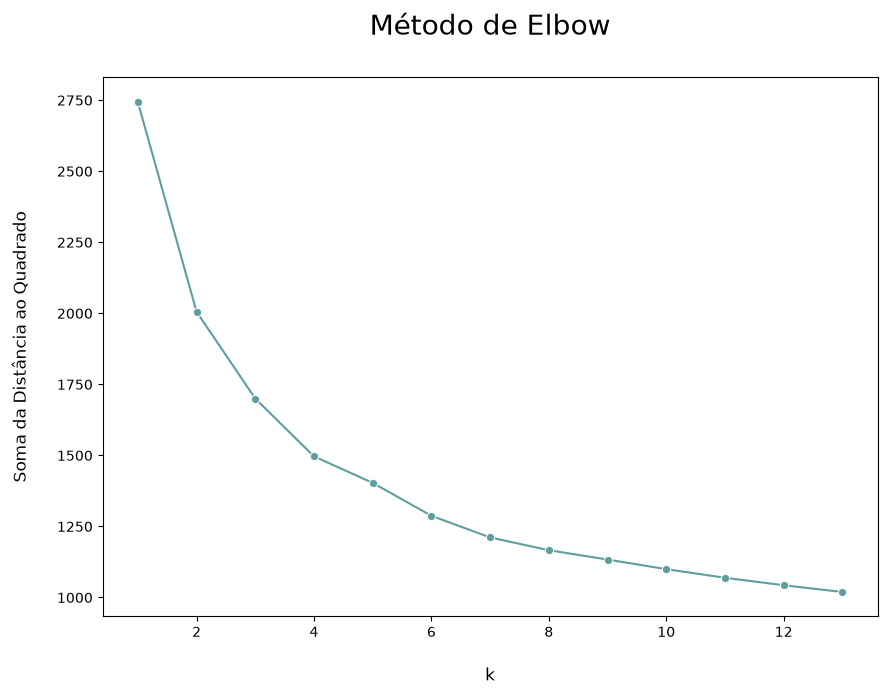

In [121]:
# Visualização gráfica para aplicar “ELBOW METHOD” (MÉTODO DO COTOVELO)
plt.figure(figsize=(10,7))
sns.lineplot(x=num_clusters, y=inertia, color='cadetblue', marker='o')
plt.xlabel('\nk', size=12)
plt.ylabel('Soma da Distância ao Quadrado\n', size=12)
plt.title('Método de Elbow\n', size=20)
plt.show()

📌 **Nota:** na versão sem pesos, a queda da inércia desacelera a partir de **k = 3 a 4** (2.744 → 2.006 → 1.700 → 1.497), e por isso o projeto original escolheu **k = 4**.

> ⚠️ Na versão original, este cálculo foi feito **antes** da alocação de pesos, mas o modelo final foi treinado **com** pesos. A seção 6.2 corrige isso.

### 6.2. Cotovelo + Silhouette (com pesos)

Recalculamos o cotovelo **na mesma base usada no treino** e adicionamos o **Silhouette Score**, que mede (de -1 a 1) o quanto cada cliente está mais próximo do próprio grupo do que dos outros grupos (**quanto maior, melhor**).

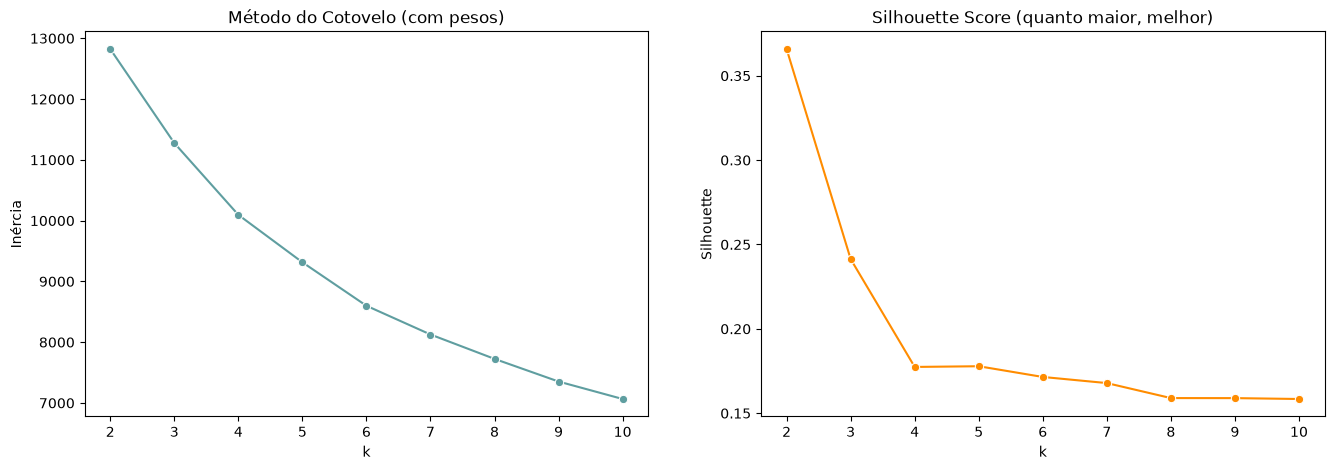

In [122]:
valores_k = range(2, 11)
inercia, silhueta = [], []

for k in valores_k:
    modelo_k = KMeans(n_clusters=k, n_init=10, random_state=42)
    rotulos = modelo_k.fit_predict(scaled_df)
    inercia.append(modelo_k.inertia_)
    silhueta.append(silhouette_score(scaled_df, rotulos))

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.lineplot(x=list(valores_k), y=inercia, marker='o', color='cadetblue', ax=ax[0])
ax[0].set(title='Método do Cotovelo (com pesos)', xlabel='k', ylabel='Inércia')
sns.lineplot(x=list(valores_k), y=silhueta, marker='o', color='darkorange', ax=ax[1])
ax[1].set(title='Silhouette Score (quanto maior, melhor)', xlabel='k', ylabel='Silhouette')
plt.savefig('../Imagens/Cotovelo e Silhouette.png', bbox_inches='tight')
plt.show()

📌 **Nota**

| k | Inércia | Silhouette |
|---|---|---|
| 2 | 12.824 | **0,366** |
| 3 | 11.277 | 0,241 |
| **4** | **10.095** | **0,177** |
| 5 | 9.315 | 0,178 |
| 6 | 8.599 | 0,171 |
| 8 | 7.725 | 0,159 |
| 10 | 7.065 | 0,158 |

- 🔎 Com os pesos, **não há um cotovelo nítido**: a inércia cai de forma gradual.
- 🔎 O melhor Silhouette é com **k = 2**, que basicamente separa clientes de **gasto alto x gasto baixo**. A partir de k = 4 o Silhouette se estabiliza (~0,16 a 0,18).
- ✅ **Decisão:** manter **k = 4**. Dois grupos seriam óbvios demais para o marketing; com 4, o gasto alto se divide em *Premium* x *Fiéis de alto volume* e o gasto baixo em *Novos e ativos* x *Em risco de churn*, que pedem **ações diferentes**. É uma escolha de **utilidade para o negócio**, com custo pequeno de separação em relação a k = 5 ou 6.

### 6.3. Sensibilidade aos pesos

Os pesos foram definidos por critério de negócio. Para saber o quanto eles **mudam os grupos**, treinamos o mesmo K-Means (k = 4) **sem pesos** e comparamos com o modelo final.

Usamos o **Adjusted Rand Index (ARI)**, que mede a concordância entre duas segmentações:
- **1** → os dois modelos formaram exatamente os mesmos grupos;
- **0** → a concordância é a mesma de grupos sorteados ao acaso.

> 💡 O ARI não depende da numeração dos clusters: se o "cluster 1" de um modelo for o "cluster 3" do outro, ele entende que é o mesmo grupo.

In [123]:
clusters_sem_pesos = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(scaled_df_sem_pesos)

print(f'ARI (com pesos x sem pesos): {adjusted_rand_score(clusters, clusters_sem_pesos):.3f}')

# Quantos clientes de cada grupo (com pesos) caíram em cada grupo (sem pesos)
pd.crosstab(clusters, clusters_sem_pesos, rownames=['Com pesos'], colnames=['Sem pesos'])

ARI (com pesos x sem pesos): 0.203


Sem pesos,0,1,2,3
Com pesos,,,,
0,113,346,103,67
1,122,12,71,363
2,105,256,57,1
3,133,13,73,368


📌 **Nota**
- 🔎 **ARI = 0,20** → baixa concordância: **os pesos mudam bastante os grupos**.
- 🔎 Sem pesos, as variáveis de percentual (mix de produtos e canais) ganham força e o modelo passa a agrupar mais por **"no que e onde compra"** do que por **"quanto vale o cliente"**.
- ✅ **Conclusão:** a segmentação final é uma segmentação **orientada a valor**, e isso é intencional (o objetivo é priorizar quem tem mais potencial de compra). Por outro lado, os pesos são uma **decisão de negócio importante** e devem ser validados com o time de marketing.

### 6.4. Comparação com Clusterização Hierárquica

Para confirmar que os grupos não são um "acaso" do K-Means, comparamos com outro algoritmo: a **Clusterização Hierárquica (Ward)**. Ela começa com cada cliente sozinho e vai **juntando os grupos mais parecidos** até sobrarem 4.

Se os dois algoritmos, que funcionam de formas diferentes, encontrarem grupos parecidos, temos mais confiança de que a segmentação reflete uma estrutura real dos dados.

In [124]:
hierarquico = AgglomerativeClustering(n_clusters=4, linkage='ward')
clusters_hierarquico = hierarquico.fit_predict(scaled_df)

comparacao_modelos = pd.DataFrame({
    'Modelo': ['K-Means', 'Hierárquico (Ward)'],
    'Silhouette': [silhouette_score(scaled_df, clusters), silhouette_score(scaled_df, clusters_hierarquico)],
}).round(3)
display(comparacao_modelos)

print(f'ARI (K-Means x Hierárquico): {adjusted_rand_score(clusters, clusters_hierarquico):.3f}')
pd.crosstab(clusters, clusters_hierarquico, rownames=['K-Means'], colnames=['Hierárquico'])

,Modelo,Silhouette
0,K-Means,0.177
1,Hierárquico (Ward),0.140


ARI (K-Means x Hierárquico): 0.365


Hierárquico,0,1,2,3
K-Means,,,,
0,524,6,10,89
1,37,266,0,265
2,179,0,240,0
3,8,357,0,222


📌 **Nota**
- 🔎 Silhouette: **K-Means 0,177** x Hierárquico 0,140 → o K-Means separa melhor os grupos.
- 🔎 **ARI = 0,37** → concordância moderada. Pela tabela cruzada, o hierárquico reproduz bem os *Fiéis de alto volume* (83% no mesmo grupo) e cria um grupo formado **só** por clientes *Premium*, mas divide de outra forma os dois grupos de baixo valor e a fronteira entre *Premium* e *Fiéis*.
- ✅ **Por que manter o K-Means?** Tem o melhor Silhouette, é mais simples de explicar e consegue **classificar clientes novos** com `predict` (o hierárquico precisaria ser refeito com a base inteira).

## 7 - AJUSTE FINO DE HIPERPARÂMETROS

No K-Means, os principais hiperparâmetros são:

| Hiperparâmetro | Valor | Por quê |
|---|---|---|
| `n_clusters` (k) | 4 | Cotovelo + Silhouette + grupos interpretáveis para o marketing |
| `n_init` | 10 | Roda o algoritmo 10 vezes com pontos de partida diferentes e fica com o melhor resultado |
| `random_state` | 42 | Garante que o resultado seja **reproduzível** (os mesmos grupos a cada execução) |

> 💡 Mais do que o melhor número estatístico, k precisa gerar grupos que o time de marketing consiga **entender e acionar**. 4 perfis é um número fácil de transformar em campanhas.

### 7.3. Modelo final

O modelo final é o **K-Means com k = 4**, treinado na seção 5 sobre a base normalizada e ponderada (`scaled_df`).

## 8 - Otimização de limiar e calibração

> 🚫 **Não se aplica (itens 8.1 a 8.4).** Limiar e calibração servem para converter **probabilidades** em classes (0/1) em modelos de classificação. O K-Means não gera probabilidades: ele atribui cada cliente diretamente a um grupo.

# FASE 04: AVALIAÇÃO

Agora verificamos se os grupos são **bons** (bem separados e com tamanhos razoáveis) e, principalmente, **o que caracteriza cada um**.

## 1 - Avaliando a Máquina Preditiva

In [125]:
# Quantas pessoas tem em cada cluster
df_final.cluster.value_counts()

cluster
0    629
3    587
1    568
2    419
Name: count, dtype: int64

📌 **Nota:** os 4 grupos têm tamanhos equilibrados (de **419** a **629** clientes), sem nenhum grupo minúsculo ou dominante.

In [126]:
print(f'Silhouette Score do modelo final: {silhouette_score(scaled_df, clusters):.3f}')

Silhouette Score do modelo final: 0.177


📌 **Como ler o Silhouette Score**
- **Próximo de 1:** grupos bem separados.
- **Próximo de 0:** grupos se sobrepõem.
- **Negativo:** clientes provavelmente no grupo errado.

🔎 O resultado de **0,177** indica grupos **com sobreposição**, algo comum em dados de clientes: o comportamento de compra é contínuo (não existem "fronteiras" rígidas entre um cliente e outro). Por isso, a qualidade da segmentação também é avaliada pela **diferença de perfil entre os grupos** (item 3), que é bem clara.

## 2 - Previsto x observado

Como não há um valor "observado" para comparar, o equivalente é **visualizar os grupos**. Usamos o **PCA** para resumir as 24 variáveis em 2 dimensões e plotar cada cliente colorido pelo seu cluster. Grupos bem separados no gráfico indicam uma boa segmentação.

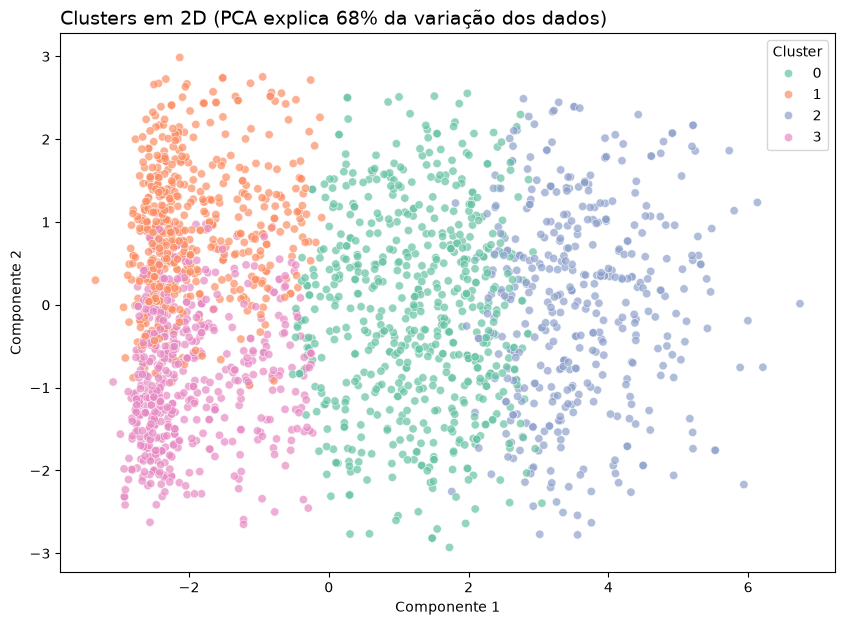

In [127]:
pca = PCA(n_components=2, random_state=42)
componentes = pca.fit_transform(scaled_df)

plt.figure(figsize=(10, 7))
sns.scatterplot(x=componentes[:, 0], y=componentes[:, 1], hue=df_final['cluster'].values,
                palette='Set2', alpha=0.7)
plt.title(f'Clusters em 2D (PCA explica {pca.explained_variance_ratio_.sum():.0%} da variação dos dados)',
          fontsize=14, loc='left')
plt.xlabel('Componente 1')
plt.ylabel('Componente 2')
plt.legend(title='Cluster')
plt.savefig('../Imagens/Clusters em 2D (PCA).png', bbox_inches='tight')
plt.show()

📌 **Nota:** as 2 componentes do PCA explicam **68%** da variação dos dados.
- 🔎 O **eixo horizontal funciona como um eixo de valor**: os clusters 1 e 3 (baixo gasto) ficam à esquerda, o cluster 0 (*Fiéis*) no meio e o cluster 2 (*Premium*) à direita.
- 🔎 Os clusters **1 e 3** se sobrepõem bastante: são parecidos em renda e gasto e se diferenciam principalmente pela **recência**. Essa sobreposição explica o Silhouette de 0,177.

## 3 - Quais variáveis mais influenciam o modelo?

Comparamos a **média de cada variável por cluster**. As variáveis em que os grupos mais diferem são as que mais "explicam" a segmentação.

In [128]:
# Média para cada uma das variáveis
df_final.groupby('cluster').mean()

,Year_Birth,Education,Income,Recency,ChildrenHome,LifeTime,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,TotalAmountSpent,AcceptedCmp,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumDealsPurchases,NumWebVisitsMonth,TotalPurchases,Marital_Status_Divorced,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow
cluster,,,,,,,,,,,,,,,,,,,,,,,,
0,1965.750397,2.562798,63507.672496,48.179650,0.839428,15.301272,0.525744,0.045880,0.234392,0.063508,0.047504,0.082973,824.597774,0.386328,0.332447,0.214439,0.453114,0.162211,4.572337,18.368839,0.111288,0.179650,0.656598,0.052464
1,1970.096831,2.320423,36556.424296,74.721831,1.279930,14.519073,0.397451,0.054050,0.246382,0.078906,0.057597,0.165613,131.633803,0.123239,0.349958,0.089438,0.560604,0.346875,6.376761,6.744718,0.103873,0.214789,0.660211,0.021127
2,1968.761337,2.596659,77120.233890,50.840095,0.295943,16.952267,0.500193,0.040271,0.307128,0.058632,0.042874,0.050902,1606.073986,1.248210,0.276666,0.308068,0.415265,0.082961,3.463007,20.317422,0.102625,0.250597,0.613365,0.033413
3,1971.238501,2.388416,36510.073254,23.642249,1.216354,14.012550,0.419883,0.054432,0.226188,0.081765,0.053054,0.164679,126.553663,0.262351,0.346142,0.081440,0.572418,0.335905,6.359455,6.582624,0.095400,0.226576,0.649063,0.028961


📌 **Nota – destaques da tabela**

| Variável | Cluster 0 | Cluster 1 | Cluster 2 | Cluster 3 |
|---|---|---|---|---|
| Clientes | 629 | 568 | 419 | 587 |
| Renda média (US$) | 63.508 | 36.556 | **77.120** | 36.510 |
| Gasto total médio (US$) | 825 | 132 | **1.606** | 127 |
| Total de compras | 18,4 | 6,7 | **20,3** | 6,6 |
| Ticket médio (US$) | 45 | 20 | **79** | 19 |
| Dias desde a última compra | 48,2 | **74,7** | 50,8 | 23,6 |
| Filhos em casa | 0,84 | 1,28 | 0,30 | 1,22 |
| Campanhas aceitas | 0,39 | 0,12 | **1,25** | 0,26 |
| % de compras com desconto | 16% | 35% | 8% | 34% |
| % do gasto em vinho | **53%** | 40% | 50% | 42% |

> ℹ️ Com `random_state=42` a numeração dos clusters é fixa. Mesmo assim, no final desta seção os clusters recebem **nomes** de acordo com o perfil, para que a leitura não dependa dos números.

As próximas comparações focam nas variáveis com maior diferença entre os grupos:

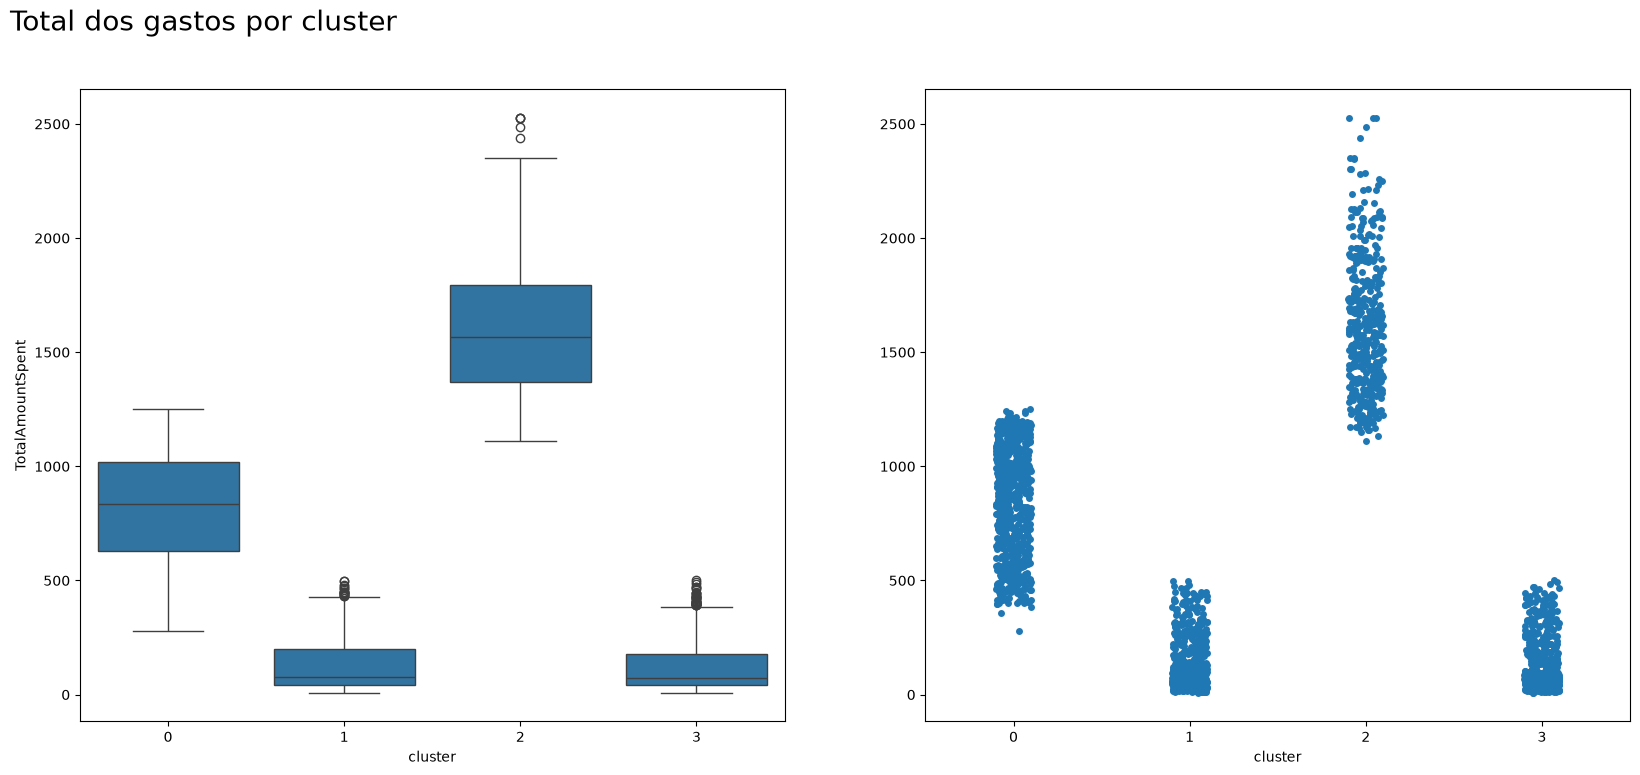

In [129]:
plot_final(df_final,'cluster','TotalAmountSpent','Total dos gastos por cluster')

📌 **Nota:** o **cluster 2** gasta muito mais que os demais; o cluster 0 vem em segundo lugar.

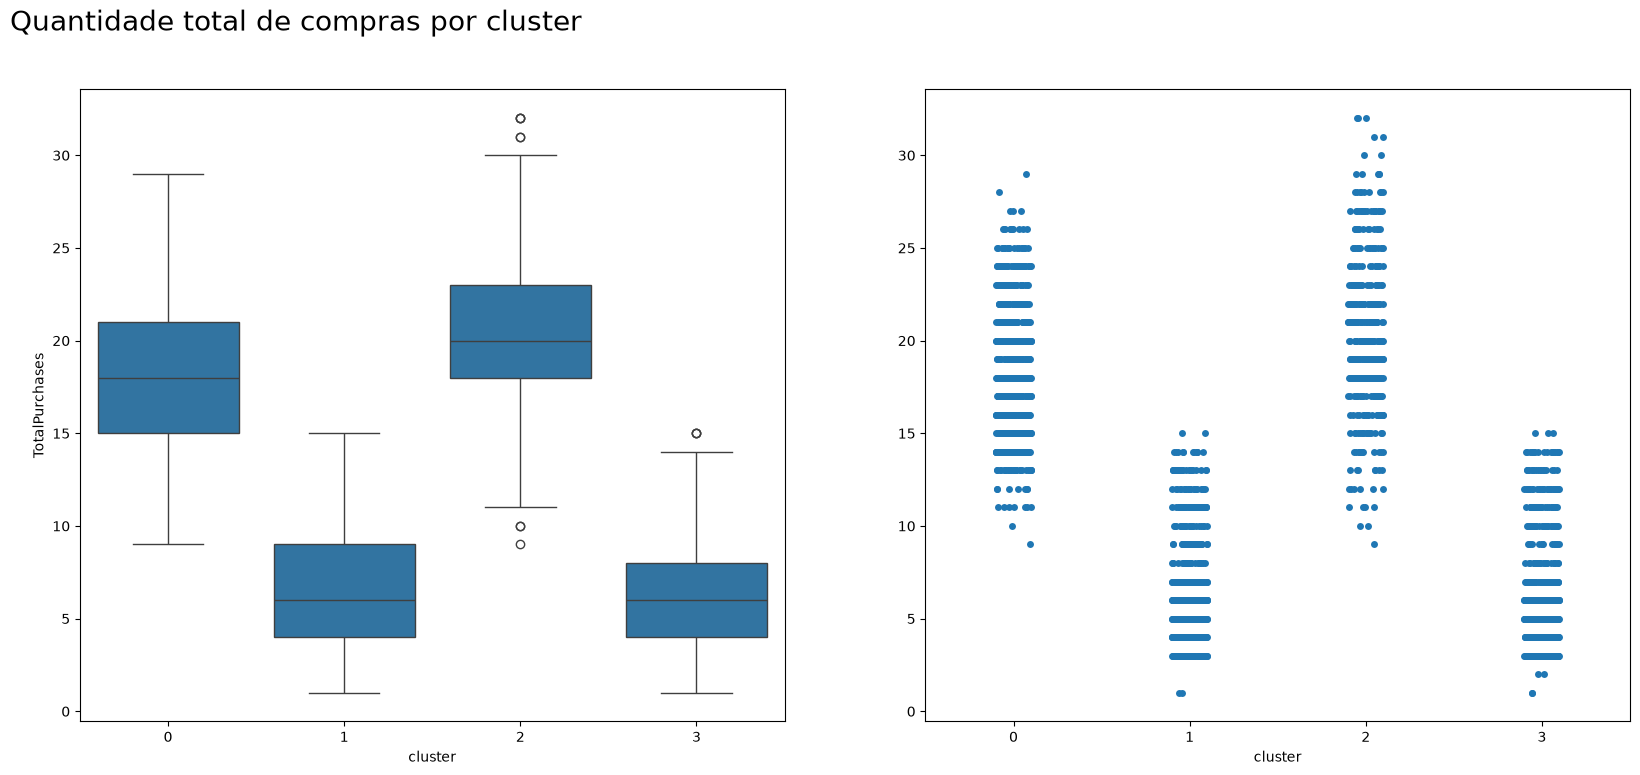

In [130]:
plot_final(df_final,'cluster','TotalPurchases','Quantidade total de compras por cluster')

📌 **Nota:** os clusters **2 e 0** compram com muito mais frequência (~18 a 20 compras) que os clusters 1 e 3 (~7 compras).

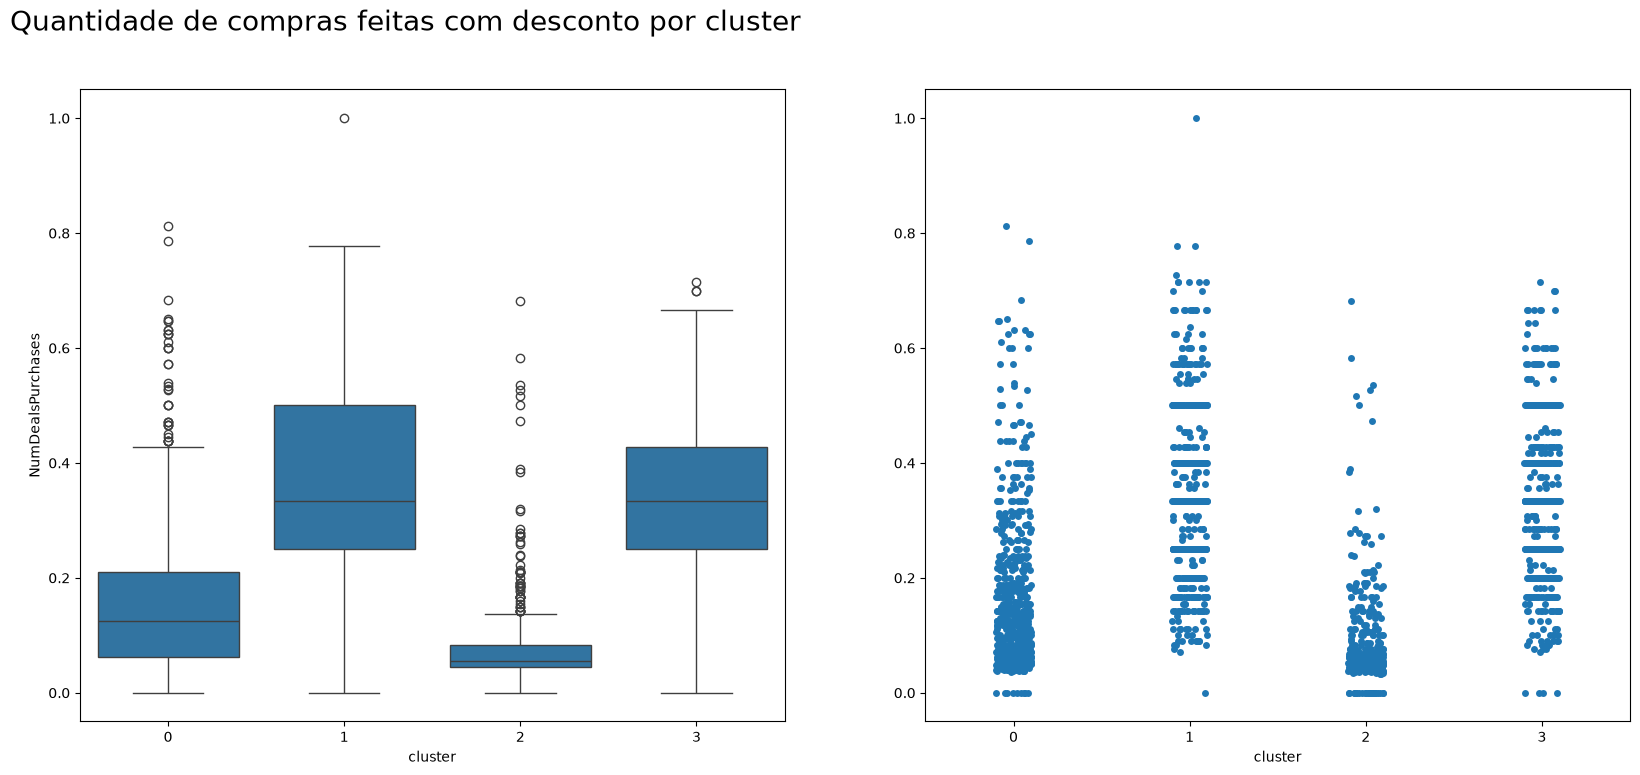

In [131]:
plot_final(df_final,'cluster','NumDealsPurchases','Quantidade de compras feitas com desconto por cluster')

📌 **Nota:** o **cluster 2** quase não compra com desconto (8%): não precisa de promoção para comprar. Os clusters 1 e 3 são os mais sensíveis a desconto (~35%).

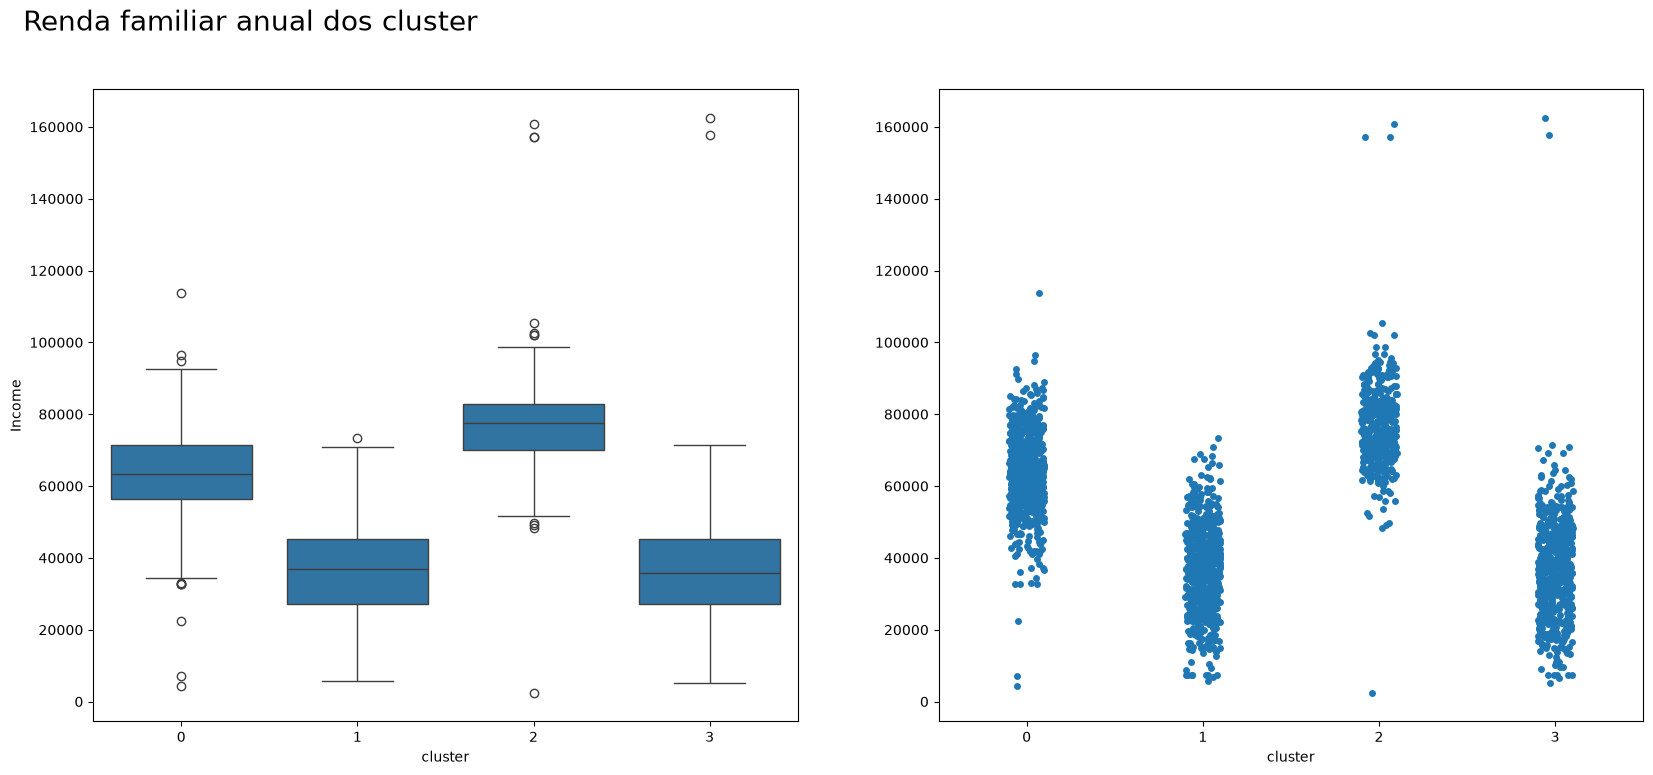

In [132]:
plot_final(df_final,'cluster','Income','Renda familiar anual dos cluster')

📌 **Nota:** os clusters **2 e 0** têm renda bem maior que os clusters 1 e 3.

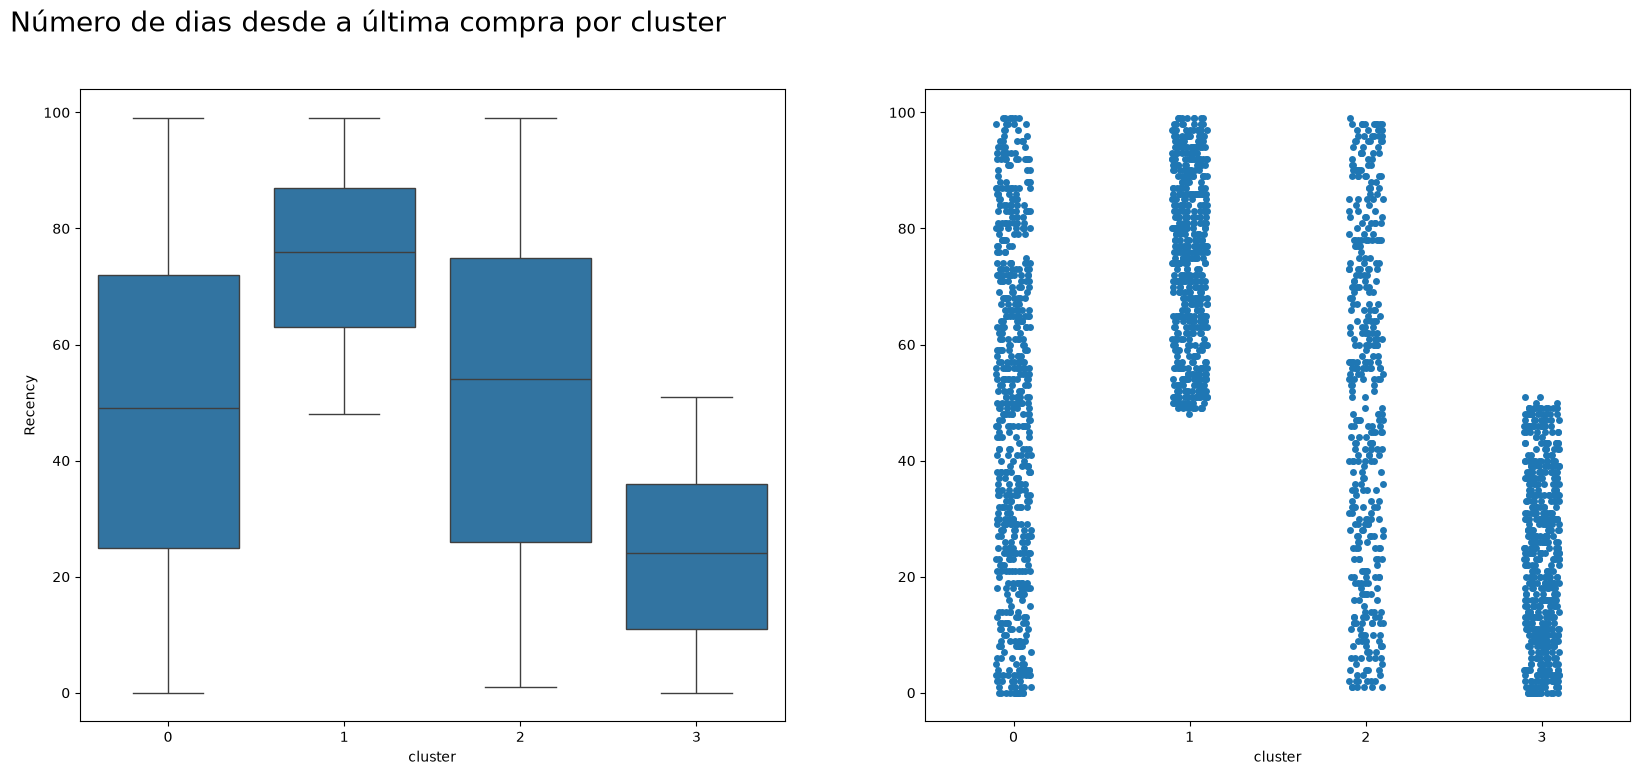

In [133]:
plot_final(df_final,'cluster','Recency','Número de dias desde a última compra por cluster')

📌 **Nota:** os clusters 1 e 3 são parecidos em renda e gasto, e a **recência** os diferencia: o cluster 3 comprou recentemente (~24 dias), enquanto o cluster 1 está há ~75 dias sem comprar → **risco de churn**.

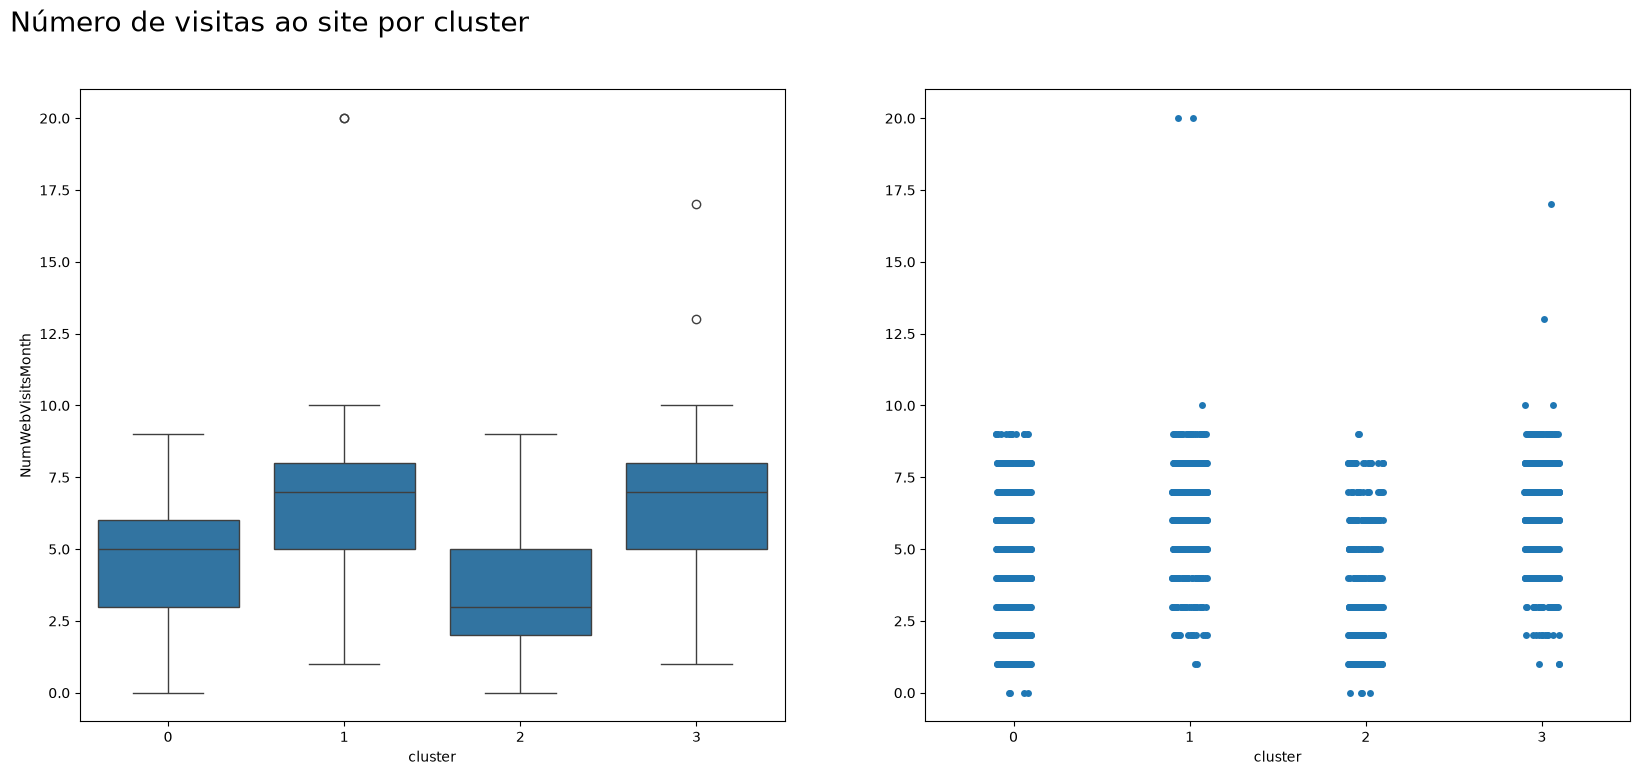

In [134]:
plot_final(df_final,'cluster','NumWebVisitsMonth','Número de visitas ao site por cluster')

📌 **Nota:** os clusters **1 e 3** são os que mais visitam o site (~6 visitas/mês), provavelmente em busca de promoções.

#### Nomeando os segmentos

O K-Means numera os grupos de forma arbitrária. Para que a análise não dependa dessa numeração, damos **nomes** aos clusters com base em regras de negócio:
- os dois de **maior gasto** são *Premium* e *Fiéis de alto volume*;
- entre os dois de **menor gasto**, o que comprou **mais recentemente** é *Novos e ativos*, e o outro é *Em risco de churn*.

In [135]:
gasto_medio = df_final.groupby('cluster')['TotalAmountSpent'].mean().sort_values(ascending=False)
premium, alto_volume = gasto_medio.index[0], gasto_medio.index[1]

menor_gasto = df_final[df_final['cluster'].isin(gasto_medio.index[2:])]
recencia_media = menor_gasto.groupby('cluster')['Recency'].mean().sort_values()
ativos, em_risco = recencia_media.index[0], recencia_media.index[1]

nomes_segmentos = {
    premium: 'Premium',
    alto_volume: 'Fiéis de alto volume',
    ativos: 'Novos e ativos',
    em_risco: 'Em risco de churn',
}
df_final['segmento'] = df_final['cluster'].map(nomes_segmentos)
df_final['segmento'].value_counts()

segmento
Fiéis de alto volume    629
Novos e ativos          587
Em risco de churn       568
Premium                 419
Name: count, dtype: int64

# FASE 05: IMPLANTAÇÃO

## 1 - Salvando o modelo

Salvamos o modelo treinado (`pickle`) na pasta `Model/` e a base com o segmento de cada cliente na pasta `Datasets/`, para uso pelo time de marketing (ex.: importar em um CRM ou no Power BI).

In [136]:
filename = '../Model/modelo_finalizado.sav'
with open(filename, 'wb') as arquivo:
    pickle.dump(Model, arquivo)

In [137]:
with open(filename, 'rb') as arquivo:
    Model = pickle.load(arquivo)

In [138]:
df_final.to_csv('../Datasets/clientes_segmentados.csv', index=False)

### Pipeline de produção

O modelo salvo acima só funciona se o cliente novo for **normalizado e ponderado exatamente como na base de treino**, e esses passos estão espalhados pelo notebook. Para evitar erros, juntamos tudo em um **`Pipeline` do scikit-learn**, que executa as etapas sempre na mesma ordem:

| Etapa | O que faz |
|---|---|
| `normalizacao` | `MinMaxScaler`: coloca as colunas entre 0 e 1, usando o mínimo e o máximo da **base de treino** |
| `pesos` | `FunctionTransformer` + `aplicar_pesos`: multiplica as colunas pelos pesos de negócio |
| `kmeans` | O K-Means com k = 4 |

> 💡 Com o pipeline, prever o segmento de um cliente novo é uma única linha: `pipeline.predict(cliente)`. O app Streamlit (final do notebook) usa este arquivo.

In [139]:
X_treino = df_final[COLUNAS_MODELO]
assert list(scaled_df.columns) == COLUNAS_MODELO, 'As colunas do modelo mudaram: atualize COLUNAS_MODELO em src/utils.py'

pipeline = Pipeline([
    ('normalizacao', MinMaxScaler()),
    ('pesos', FunctionTransformer(aplicar_pesos, kw_args={'pesos': PESOS}, feature_names_out='one-to-one')),
    ('kmeans', KMeans(n_clusters=4, n_init=10, random_state=42)),
]).set_output(transform='pandas')

pipeline.fit(X_treino)

# Checagem: mesmo pré-processamento + mesma semente → os mesmos grupos do modelo treinado na Fase 03
print(f'Concordância com o modelo da Fase 03: {(pipeline.predict(X_treino) == clusters).mean():.0%}')

Concordância com o modelo da Fase 03: 100%


In [140]:
modelo_producao = {
    'pipeline': pipeline,
    'colunas': COLUNAS_MODELO,
    'segmentos': {int(cluster): nome for cluster, nome in nomes_segmentos.items()},
    'perfil_medio': df_final.groupby('segmento')[['Income', 'TotalAmountSpent', 'TotalPurchases',
                                                  'Recency', 'ChildrenHome', 'AcceptedCmp']].mean(),
}

with open('../Model/pipeline_segmentacao.pkl', 'wb') as arquivo:
    pickle.dump(modelo_producao, arquivo)

## 2 - Aplicando uma simulação

Simulamos a chegada de um **novo cliente** com os dados no formato original da base (valores em US$ e quantidade de compras). A função `preparar_cliente` aplica o **mesmo Feature Engineering** do notebook (escolaridade em números, totais, percentuais e estado civil em colunas 0/1), e o pipeline indica o segmento.

In [141]:
novo_cliente = {
    'Year_Birth': 1968, 'Education': 'Master', 'Marital_Status': 'Married',
    'Income': 80000, 'Kidhome': 0, 'Teenhome': 0, 'LifeTime': 18, 'Recency': 30,
    'MntWines': 750, 'MntFruits': 60, 'MntMeatProducts': 450,
    'MntFishProducts': 90, 'MntSweetProducts': 75, 'MntGoldProds': 75,
    'NumWebPurchases': 6, 'NumCatalogPurchases': 6, 'NumStorePurchases': 8,
    'NumDealsPurchases': 1, 'NumWebVisitsMonth': 3, 'AcceptedCmp': 1,
}

cliente_preparado = preparar_cliente(novo_cliente)
display(cliente_preparado)

cluster_previsto = pipeline.predict(cliente_preparado)[0]
print(f'Cluster previsto: {cluster_previsto} → segmento: {nomes_segmentos[cluster_previsto]}')

,Year_Birth,Education,Income,Recency,ChildrenHome,LifeTime,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,TotalAmountSpent,AcceptedCmp,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumDealsPurchases,NumWebVisitsMonth,TotalPurchases,Marital_Status_Divorced,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow
0,1968,3,80000,30,0,18,0.5,0.04,0.3,0.06,0.05,0.05,1500,1,0.3,0.3,0.4,0.05,3,20,0,0,1,0


Cluster previsto: 2 → segmento: Premium


📌 **Nota:** um cliente com renda alta, gasto alto (US$ 1.500), muitas compras (20) e quase nenhuma compra com desconto deve ser classificado como **Premium**.

# 💡 INSIGHTS

Com os perfis definidos, cada segmento recebe uma estratégia de marketing.

### 🥇 Premium (cluster 2 · 419 clientes · 19%)
- **Perfil:** maior renda (~US$ 77 mil/ano) e escolaridade; poucos filhos em casa; são clientes há mais tempo.
- **Comportamento:** maior gasto (~US$ 1.606 em 2 anos, **50% de todo o gasto da base**) e **maior ticket médio** (~US$ 79 por compra). Preferem **catálogo e loja física**, quase não usam desconto, têm a maior participação de **carnes** no gasto e são os que **mais aceitam campanhas** (1,25 em média).
- **Ação:** 🎯 **público prioritário do novo produto.** Ofertas exclusivas e lançamentos via catálogo, sem necessidade de desconto.

> *Ticket médio = gasto total ÷ número de compras.*

### 🍷 Fiéis de alto volume (cluster 0 · 629 clientes · 29%)
- **Perfil:** renda alta (~US$ 64 mil/ano), os clientes mais velhos da base, com ~1 filho em casa em média.
- **Comportamento:** compram muito (~18 compras), mas com ticket médio menor (~US$ 45). Têm o maior gasto proporcional com **vinhos** (53%), formam o maior grupo da base e respondem por **39% do gasto total**.
- **Ação:** 🎯 **segundo público do lançamento.** Combos e programa de fidelidade, especialmente com vinhos.

### 🌱 Novos e ativos (cluster 3 · 587 clientes · 27%)
- **Perfil:** clientes mais jovens e cadastrados há menos tempo; renda menor (~US$ 37 mil/ano); filhos em casa.
- **Comportamento:** **compraram há pouco tempo** (~24 dias), gasto baixo, sensíveis a desconto e visitam bastante o site.
- **Ação:** campanhas digitais com desconto para aumentar o ticket médio e criar o hábito de compra.

### ⚠️ Em risco de churn (cluster 1 · 568 clientes · 26%)
- **Perfil:** renda menor (~US$ 37 mil/ano); mais filhos em casa.
- **Comportamento:** **mais tempo sem comprar** (~75 dias), gasto baixo, compram muito com desconto, maior proporção de gasto com ouro e a **menor aceitação de campanhas** (0,12).
- **Ação:** campanhas de **reativação** (cupons, produtos para a família e o público infantil). Não é o público ideal para o lançamento.

### ✅ Resposta à pergunta de negócio

> Priorizar o lançamento no segmento **Premium** (maior gasto e maior aceitação de campanhas) e, em seguida, nos **Fiéis de alto volume**. Juntos, eles representam **48% dos clientes** (1.048 de 2.203), mas **~89% do gasto total**. A campanha fala com **~52% menos clientes**, ficando mais barata e mais assertiva do que falar com a base inteira.

# 🚀 PRÓXIMOS PASSOS

1. **Medir o resultado de negócio:** acompanhar a conversão da campanha do novo produto por segmento (teste A/B entre o segmento priorizado e a base geral).
2. **Publicar o app** no Streamlit Community Cloud e gravar um GIF de demonstração para o README.
3. **Refinar os perfis** com análises dentro de cada cluster (ex.: mix de produtos e canais preferidos).
4. **Atualizar a segmentação periodicamente**, já que o comportamento dos clientes muda com o tempo.

# 🖥️ Interface com Streamlit

Para que o time de marketing consiga usar o modelo **sem abrir o notebook**, criamos um app simples em **Streamlit**:
1. O usuário preenche os dados do cliente na barra lateral (valores em US$, quantidade de compras etc.).
2. O app aplica o mesmo Feature Engineering (`preparar_cliente`) e o pipeline salvo na Fase 05.
3. Mostra o **segmento**, a **ação de marketing recomendada** e uma comparação do cliente com a média do segmento.

A célula abaixo grava o arquivo `app.py` na raiz do projeto. Para executar o app (a partir da raiz do projeto, depois de rodar a Fase 05, que gera `Model/pipeline_segmentacao.pkl`):

```bash
pip install -r requirements.txt
streamlit run app.py
```

In [142]:
%%writefile ../app.py
import pickle
from pathlib import Path

import pandas as pd
import streamlit as st

from src.utils import preparar_cliente

st.set_page_config(page_title="Segmentação de Clientes 🛒", page_icon="🛒", layout="wide")
st.title("🛒 Segmentação de Clientes")
st.markdown("Preencha os dados do cliente na barra lateral e descubra a qual **segmento** ele pertence.")

CAMINHO_MODELO = Path(__file__).parent / "Model" / "pipeline_segmentacao.pkl"

# Descrição e ação de marketing de cada segmento
SEGMENTOS = {
    "Premium": {
        "emoji": "🥇",
        "descricao": "Maior renda e maior gasto. Compram por catálogo e na loja, quase não usam desconto e são os que mais aceitam campanhas.",
        "acao": "Público prioritário do novo produto: ofertas exclusivas e lançamentos, sem necessidade de desconto.",
    },
    "Fiéis de alto volume": {
        "emoji": "🍷",
        "descricao": "Renda alta, compram com frequência e têm o vinho como categoria preferida.",
        "acao": "Segundo público do lançamento: combos e programa de fidelidade.",
    },
    "Novos e ativos": {
        "emoji": "🌱",
        "descricao": "Clientes mais jovens e recentes, compraram há pouco tempo, gasto baixo e sensíveis a desconto.",
        "acao": "Campanhas digitais com desconto para aumentar o ticket médio.",
    },
    "Em risco de churn": {
        "emoji": "⚠️",
        "descricao": "Muito tempo sem comprar, gasto baixo, compram com desconto e quase não respondem a campanhas.",
        "acao": "Campanhas de reativação com cupons e produtos para a família.",
    },
}


### Carregamento do modelo
@st.cache_resource
def carregar_modelo(caminho):
    with open(caminho, "rb") as arquivo:
        return pickle.load(arquivo)


if not CAMINHO_MODELO.exists():
    st.error("Modelo não encontrado. Execute o notebook até a Fase 05 para gerar `Model/pipeline_segmentacao.pkl`.")
    st.stop()

modelo = carregar_modelo(CAMINHO_MODELO)

### Formulário com os dados do cliente
with st.sidebar:
    st.header("👤 Perfil")
    year_birth = st.number_input("Ano de nascimento", 1930, 2000, 1970)
    education = st.selectbox("Escolaridade", ["Basic", "2n Cycle", "Graduation", "Master", "PhD"], index=2)
    marital_status = st.selectbox("Estado civil", ["Single", "Together", "Married", "Divorced", "Widow"])
    income = st.number_input("Renda anual (US$)", 0, 200000, 50000, step=1000)
    kidhome = st.number_input("Crianças em casa", 0, 5, 0)
    teenhome = st.number_input("Adolescentes em casa", 0, 5, 0)
    lifetime = st.number_input("Meses como cliente", 0, 60, 15)
    recency = st.number_input("Dias desde a última compra", 0, 365, 30)

    st.header("🛍️ Gastos nos últimos 2 anos (US$)")
    mnt_wines = st.number_input("Vinhos", 0, 5000, 300)
    mnt_fruits = st.number_input("Frutas", 0, 5000, 25)
    mnt_meat = st.number_input("Carnes", 0, 5000, 150)
    mnt_fish = st.number_input("Peixes", 0, 5000, 35)
    mnt_sweet = st.number_input("Doces", 0, 5000, 25)
    mnt_gold = st.number_input("Ouro", 0, 5000, 40)

    st.header("🏬 Compras e campanhas")
    num_web = st.number_input("Compras pelo site", 0, 50, 4)
    num_catalog = st.number_input("Compras por catálogo", 0, 50, 2)
    num_store = st.number_input("Compras na loja", 0, 50, 6)
    num_deals = st.number_input("Compras com desconto", 0, 50, 2)
    num_visits = st.number_input("Visitas ao site no último mês", 0, 30, 5)
    accepted_cmp = st.slider("Campanhas aceitas (de 6)", 0, 6, 0)

dados = {
    "Year_Birth": year_birth, "Education": education, "Marital_Status": marital_status,
    "Income": income, "Kidhome": kidhome, "Teenhome": teenhome,
    "LifeTime": lifetime, "Recency": recency,
    "MntWines": mnt_wines, "MntFruits": mnt_fruits, "MntMeatProducts": mnt_meat,
    "MntFishProducts": mnt_fish, "MntSweetProducts": mnt_sweet, "MntGoldProds": mnt_gold,
    "NumWebPurchases": num_web, "NumCatalogPurchases": num_catalog, "NumStorePurchases": num_store,
    "NumDealsPurchases": num_deals, "NumWebVisitsMonth": num_visits, "AcceptedCmp": accepted_cmp,
}

### Previsão
if st.button("Identificar segmento", type="primary"):
    try:
        cliente = preparar_cliente(dados)
    except ValueError as erro:
        st.warning(str(erro))
        st.stop()

    cluster = modelo["pipeline"].predict(cliente)[0]
    segmento = modelo["segmentos"][cluster]
    info = SEGMENTOS[segmento]

    st.subheader(f"{info['emoji']} Segmento: {segmento}")
    st.markdown(f"**Perfil:** {info['descricao']}")
    st.success(f"**Ação recomendada:** {info['acao']}")

    # Comparação do cliente com a média do segmento
    perfil_medio = modelo["perfil_medio"].loc[segmento]
    comparacao = pd.DataFrame({
        "Cliente": cliente[perfil_medio.index].iloc[0],
        f"Média do segmento {segmento}": perfil_medio,
    }).round(1)
    comparacao.index = ["Renda anual", "Gasto total", "Total de compras", "Dias desde a última compra",
                        "Filhos em casa", "Campanhas aceitas"]
    st.markdown("#### Cliente x média do segmento")
    st.dataframe(comparacao, width="stretch")

Overwriting ../app.py